# Part A - Zoo Visitor Spending Regression

The aim of Part A is to predict `VisitSpending` using visitor and visit-related information. The dataset is first explored and cleaned before two regression models are trained and evaluated on unseen test data.

In [349]:
# Import the libraries used in Part A

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


# Set a random seed so the results can be reproduced
RANDOM_SEED = 42

## A1. Dataset Exploration

In [350]:
 # Load the zoo visitor spending dataset

df = pd.read_csv("Zoo Visitor Spending(in).csv")


# Show the first 5 rows
print("First 5 rows:")
display(df.head())

First 5 rows:


,VisitSpending,PartySize,MilesFromZoo,Member,NumberOfChildren,VisitDurationHours,WeekendVisit,Season,SpecialEvent,AdvanceBooking,WeatherCondition
0,98.48,6,55.0,0,2.0,4.4,0,Autumn,0,0,Rainy
1,91.83,1,131.0,0,0.0,4.0,1,Spring,1,1,Sunny
2,161.15,2,158.0,0,0.0,2.2,0,Spring,0,0,Sunny
3,166.92,5,161.0,0,1.0,3.2,0,Summer,0,0,Rainy
4,115.28,8,32.0,1,3.0,3.2,0,Spring,0,0,Sunny


In [351]:
# Check the size of the dataset

print("Dataset shape:")
print(df.shape)


# Show all column names
print("\nColumn names:")
print(df.columns.tolist())


# Check data types and non-missing values
print("\nDataset information:")
df.info()

Dataset shape:
(2000, 11)

Column names:
['VisitSpending', 'PartySize', 'MilesFromZoo', 'Member', 'NumberOfChildren', 'VisitDurationHours', 'WeekendVisit', 'Season', 'SpecialEvent', 'AdvanceBooking', 'WeatherCondition']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   VisitSpending       2000 non-null   float64
 1   PartySize           2000 non-null   int64  
 2   MilesFromZoo        1965 non-null   float64
 3   Member              2000 non-null   int64  
 4   NumberOfChildren    1975 non-null   float64
 5   VisitDurationHours  1970 non-null   float64
 6   WeekendVisit        2000 non-null   int64  
 7   Season              2000 non-null   str    
 8   SpecialEvent        2000 non-null   int64  
 9   AdvanceBooking      2000 non-null   int64  
 10  WeatherCondition    1980 non-null   str    
dtypes: float64(4), int64

In [352]:
# Show summary statistics for the numerical columns

print("Summary statistics:")

display(df.describe())

Summary statistics:


,VisitSpending,PartySize,MilesFromZoo,Member,NumberOfChildren,VisitDurationHours,WeekendVisit,SpecialEvent,AdvanceBooking
count,2000.000000,2000.000000,1965.000000,2000.00000,1975.000000,1970.000000,2000.000000,2000.000000,2000.000000
mean,103.564615,4.336000,71.191349,0.56950,1.111899,3.492995,0.527000,0.100500,0.575000
std,55.033836,2.149282,45.269481,0.49527,1.132613,0.871990,0.499395,0.300741,0.494467
min,4.590000,1.000000,1.000000,0.00000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,63.407500,3.000000,35.000000,0.00000,0.000000,2.900000,0.000000,0.000000,0.000000
50%,98.095000,4.000000,61.000000,1.00000,1.000000,3.500000,1.000000,0.000000,1.000000
75%,140.157500,6.000000,102.000000,1.00000,2.000000,4.100000,1.000000,0.000000,1.000000
max,293.110000,10.000000,180.000000,1.00000,5.000000,6.700000,1.000000,1.000000,1.000000


### Categorical Variables

In [353]:
# Check the values stored in the categorical columns

print("Season values:")
print(df["Season"].value_counts(dropna=False))


print("\nWeather condition values:")
print(df["WeatherCondition"].value_counts(dropna=False))

Season values:
Season
Summer    653
Autumn    544
Spring    465
Winter    338
Name: count, dtype: int64

Weather condition values:
WeatherCondition
Sunny     915
Cloudy    710
Rainy     355
NaN        20
Name: count, dtype: int64


### Missing Values and Duplicate Records

In [354]:
# Check how many missing values each column contains

print("Missing values:")
print(df.isnull().sum())


# Check for exact duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
VisitSpending          0
PartySize              0
MilesFromZoo          35
Member                 0
NumberOfChildren      25
VisitDurationHours    30
WeekendVisit           0
Season                 0
SpecialEvent           0
AdvanceBooking         0
WeatherCondition      20
dtype: int64

Duplicate rows:
10


## A2. Data Cleaning and Exploratory Analysis

Duplicate records are removed before modelling so that repeated observations do not have unnecessary influence on the models. Missing values are handled later using statistics calculated from the training data to reduce the risk of data leakage.

In [355]:
# Make a copy of the original dataset

clean_df = df.copy()


# Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()


# Check the new dataset size
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(clean_df))

Original rows: 2000
Rows after removing duplicates: 1990


In [356]:
# Look at the main statistics for VisitSpending

print("Visit Spending statistics:")

display(clean_df["VisitSpending"].describe())

Visit Spending statistics:


count    1990.000000
mean      103.624824
std        55.054284
min         4.590000
25%        63.472500
50%        98.095000
75%       140.192500
max       293.110000
Name: VisitSpending, dtype: float64

### Exploratory Data Analysis

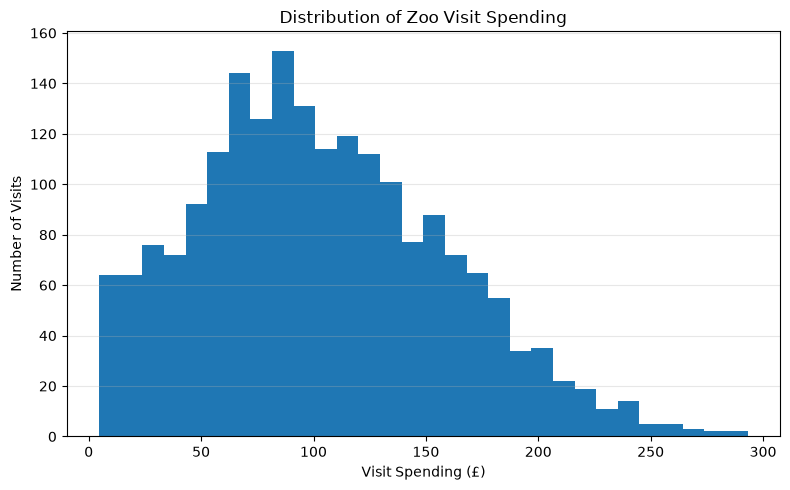

In [357]:
# Show the distribution of visitor spending
# This helps us understand whether most visitors spend similar amounts
# or whether spending varies greatly between groups

plt.figure(figsize=(8, 5))

plt.hist(
    clean_df["VisitSpending"],
    bins=30
)

plt.title("Distribution of Zoo Visit Spending")
plt.xlabel("Visit Spending (£)")
plt.ylabel("Number of Visits")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [358]:
# Select the numerical columns

numeric_columns = [
    "VisitSpending",
    "PartySize",
    "MilesFromZoo",
    "Member",
    "NumberOfChildren",
    "VisitDurationHours",
    "WeekendVisit",
    "SpecialEvent",
    "AdvanceBooking"
]


# Calculate correlations with VisitSpending

correlations = clean_df[numeric_columns].corr()["VisitSpending"]


# Sort the correlations from highest to lowest

correlations = correlations.sort_values(
    ascending=False
)


print("Correlation with VisitSpending:")
print(correlations)

Correlation with VisitSpending:
VisitSpending         1.000000
MilesFromZoo          0.754489
PartySize             0.446365
VisitDurationHours    0.350828
NumberOfChildren      0.319963
SpecialEvent          0.078813
AdvanceBooking        0.030827
WeekendVisit          0.030451
Member               -0.356659
Name: VisitSpending, dtype: float64


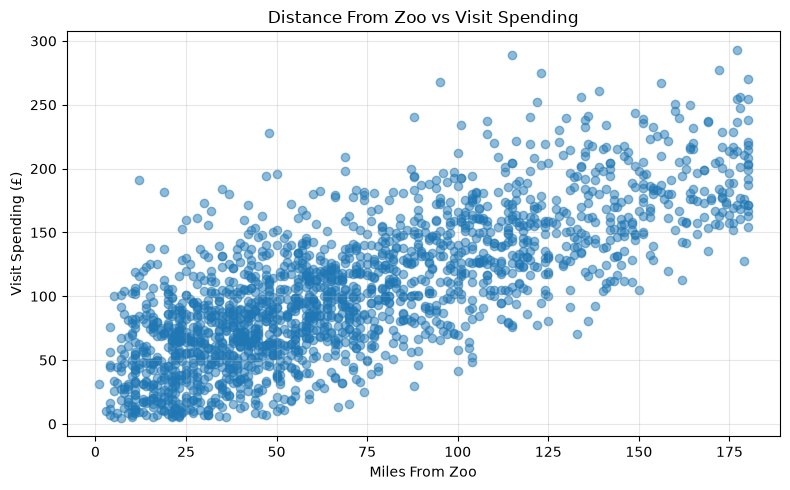

In [359]:
# Compare distance from the zoo with visitor spending
# The initial correlation check shows that distance has a strong relationship
# with VisitSpending

plt.figure(figsize=(8, 5))

plt.scatter(
    clean_df["MilesFromZoo"],
    clean_df["VisitSpending"],
    alpha=0.5
)

plt.title("Distance From Zoo vs Visit Spending")
plt.xlabel("Miles From Zoo")
plt.ylabel("Visit Spending (£)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

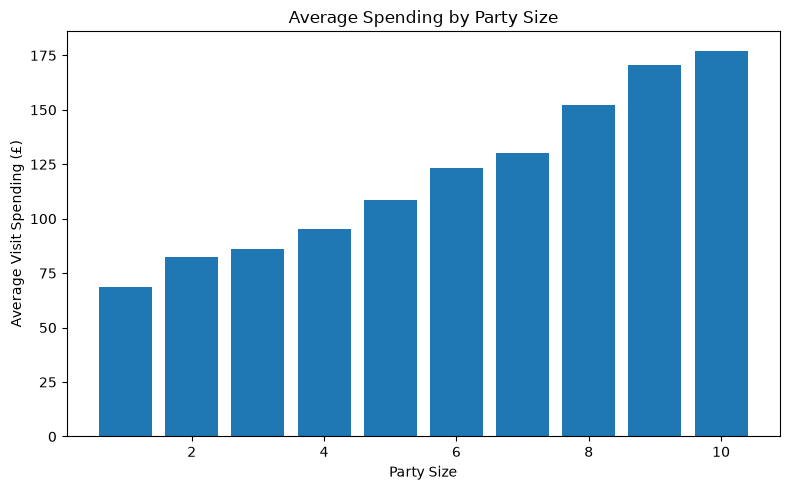

In [360]:
# Calculate average spending for each party size

party_spending = clean_df.groupby(
    "PartySize"
)["VisitSpending"].mean()


# Plot the average spending

plt.figure(figsize=(8, 5))

plt.bar(
    party_spending.index,
    party_spending.values
)

plt.title("Average Spending by Party Size")
plt.xlabel("Party Size")
plt.ylabel("Average Visit Spending (£)")

plt.tight_layout()
plt.show()

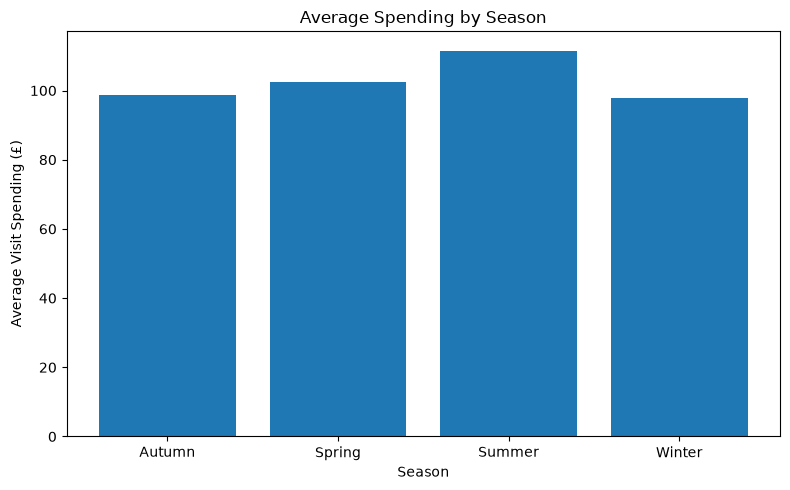

In [361]:
# Calculate average spending for each season

season_spending = clean_df.groupby(
    "Season"
)["VisitSpending"].mean()


# Plot average spending by season

plt.figure(figsize=(8, 5))

plt.bar(
    season_spending.index,
    season_spending.values
)

plt.title("Average Spending by Season")
plt.xlabel("Season")
plt.ylabel("Average Visit Spending (£)")

plt.tight_layout()
plt.show()

Average spending by membership status:
Member
0    126.196313
1     86.551774
Name: VisitSpending, dtype: float64


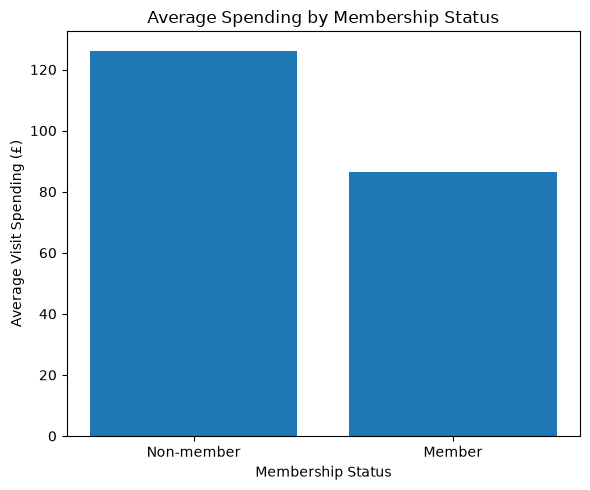

In [362]:
# Compare average spending between members and non-members

member_spending = clean_df.groupby(
    "Member"
)["VisitSpending"].mean()


print("Average spending by membership status:")
print(member_spending)


plt.figure(figsize=(6, 5))

plt.bar(
    ["Non-member", "Member"],
    member_spending.values
)

plt.title("Average Spending by Membership Status")
plt.xlabel("Membership Status")
plt.ylabel("Average Visit Spending (£)")

plt.tight_layout()
plt.show()

In [363]:
# addition

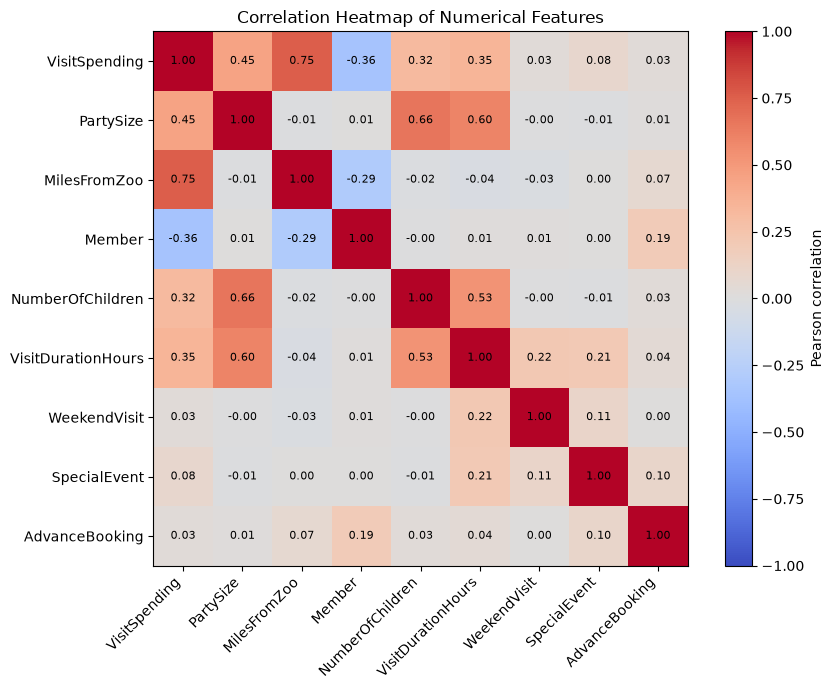

Skewness of VisitSpending: 0.428
Outliers by the 1.5 x IQR rule: 10
Smallest / largest spending: 4.59 / 293.11


In [364]:
corr_matrix = clean_df[numeric_columns].corr()

plt.figure(figsize=(9, 7))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Check the target for skew and for outliers using the 1.5 x IQR rule
spending = clean_df["VisitSpending"]
q1, q3 = spending.quantile(0.25), spending.quantile(0.75)
iqr = q3 - q1
outliers = spending[(spending < q1 - 1.5 * iqr) | (spending > q3 + 1.5 * iqr)]

print("Skewness of VisitSpending:", round(spending.skew(), 3))
print("Outliers by the 1.5 x IQR rule:", len(outliers))
print("Smallest / largest spending:", spending.min(), "/", spending.max())

The exploratory analysis shows that several visitor characteristics are associated with spending. `MilesFromZoo` has the strongest numerical relationship with `VisitSpending`, while party size and visit duration also appear relevant. Differences are also visible between categories such as season and membership status. These relationships justify using the available variables as predictors, although the observed associations should not be interpreted as proof of causation.

## A3. Data Preparation

`VisitSpending` is used as the target variable, while all remaining columns are used as input features. The data is divided into training and test sets so that final model performance can be measured using observations that were not used for training.

In [365]:
# VisitSpending is the value we want the model to predict

y = clean_df["VisitSpending"]


# X contains all the information the model can use to make the prediction

X = clean_df.drop(
    "VisitSpending",
    axis=1
)


print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (1990, 10)
Target data shape: (1990,)


In [366]:
# Split the dataset into training and test data
#
# 80% is used to train the models
# 20% is kept separate to test how well the models work on unseen data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_SEED
)


print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 1592
Testing rows: 398


In [367]:
# These columns contain numerical values

numerical_columns = [
    "PartySize",
    "MilesFromZoo",
    "Member",
    "NumberOfChildren",
    "VisitDurationHours",
    "WeekendVisit",
    "SpecialEvent",
    "AdvanceBooking"
]


# These columns contain text categories

categorical_columns = [
    "Season",
    "WeatherCondition"
]

### Missing Values and Categorical Encoding

Missing numerical values are replaced using the median calculated from the training set because the median is less sensitive to extreme values than the mean. Missing categorical values are replaced using the most frequent training-set category.

The replacement values are calculated from the training data and then applied to the test data to avoid using information from the test set during model preparation. The categorical variables `Season` and `WeatherCondition` are converted into dummy variables so that they can be used by the regression models.

In [368]:
# Fill missing numerical values using the median from the training data
#
# We use values from the training set only so information from the test set
# does not influence the model during training

for column in numerical_columns:

    median_value = X_train[column].median()

    X_train[column] = X_train[column].fillna(
        median_value
    )

    X_test[column] = X_test[column].fillna(
        median_value
    )

In [369]:
# Fill missing categorical values using the most common value
# from the training data

for column in categorical_columns:

    most_common_value = X_train[column].mode()[0]

    X_train[column] = X_train[column].fillna(
        most_common_value
    )

    X_test[column] = X_test[column].fillna(
        most_common_value
    )

In [370]:
# Machine learning models need numerical inputs
#
# get_dummies converts categories such as Summer, Winter, Sunny and Rainy
# into separate 0/1 columns

X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    drop_first=True
)


# Make sure the training and test sets contain exactly the same columns

X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)


print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (1592, 13)
Test data shape: (398, 13)


In [371]:
# Check that no missing values remain

print(
    "Missing values in training data:",
    X_train.isnull().sum().sum()
)

print(
    "Missing values in test data:",
    X_test.isnull().sum().sum()
)


# Show the final model input columns

print("\nFinal input columns:")

print(X_train.columns.tolist())

Missing values in training data: 0
Missing values in test data: 0

Final input columns:
['PartySize', 'MilesFromZoo', 'Member', 'NumberOfChildren', 'VisitDurationHours', 'WeekendVisit', 'SpecialEvent', 'AdvanceBooking', 'Season_Spring', 'Season_Summer', 'Season_Winter', 'WeatherCondition_Rainy', 'WeatherCondition_Sunny']


## A4. Regression Models

Two different regression approaches are compared. Linear Regression provides a simple model for learning linear relationships between the features and visitor spending. Random Forest Regression provides a more flexible non-linear approach by combining predictions from multiple decision trees.

In [372]:
# Create a Linear Regression model
#
# This is used as a simple baseline model.
# It estimates spending using a linear relationship between the features
# and VisitSpending.

linear_model = LinearRegression()


# Train the model using the training data

linear_model.fit(
    X_train,
    y_train
)


print("Linear Regression training complete.")

Linear Regression training complete.


In [373]:
# Create a Random Forest regression model
#
# A Random Forest combines many decision trees.
# It can learn more complicated and non-linear relationships.
#
# n_estimators=100 means that the model uses 100 decision trees.

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_SEED
)


# Train the model

random_forest_model.fit(
    X_train,
    y_train
)


print("Random Forest training complete.")

Random Forest training complete.


In [374]:
# Use both trained models to predict spending for the test data

linear_predictions = linear_model.predict(
    X_test
)

random_forest_predictions = random_forest_model.predict(
    X_test
)

In [375]:
# addition 

In [376]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold, cross_validate, GridSearchCV

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
CV_SCORING = "neg_root_mean_squared_error"

# Regularised linear models: the penalty strength (alpha) is chosen by internal cross-validation
regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        RidgeCV(alphas=np.logspace(-3, 3, 50), cv=kfold)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(),
        LassoCV(alphas=np.logspace(-3, 1, 50), cv=kfold, max_iter=20000, random_state=RANDOM_SEED)
    ),
}

# Cross-validated RMSE on the TRAINING data only
cv_rmse = {}
cv_rmse_std = {}

for name, model in regression_models.items():
    scores = cross_validate(model, X_train, y_train, cv=kfold, scoring=CV_SCORING)
    cv_rmse[name] = -scores["test_score"].mean()
    cv_rmse_std[name] = scores["test_score"].std()

# Tuned tree-based models (grid search with the same folds)
tree_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_SEED),
    param_grid={"max_depth": [3, 5, 7, 10, None], "min_samples_leaf": [1, 5, 10, 20]},
    cv=kfold, scoring=CV_SCORING, n_jobs=-1
)
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_SEED),
    param_grid={
        "n_estimators": [100, 300],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 3, 5],
        "max_features": [1.0, 0.5],
    },
    cv=kfold, scoring=CV_SCORING, n_jobs=-1
)

tree_search.fit(X_train, y_train)
rf_search.fit(X_train, y_train)

# For tuned models the best CV score is the one used to pick the settings, so it is slightly optimistic
cv_rmse["Decision Tree (tuned)"] = -tree_search.best_score_
cv_rmse_std["Decision Tree (tuned)"] = tree_search.cv_results_["std_test_score"][tree_search.best_index_]
cv_rmse["Random Forest (tuned)"] = -rf_search.best_score_
cv_rmse_std["Random Forest (tuned)"] = rf_search.cv_results_["std_test_score"][rf_search.best_index_]

print("Best Decision Tree settings:", tree_search.best_params_)
print("Best Random Forest settings:", rf_search.best_params_)

# Fit every model on the full training set
fitted_models = {}
for name, model in regression_models.items():
    fitted_models[name] = model.fit(X_train, y_train)
fitted_models["Decision Tree (tuned)"] = tree_search.best_estimator_
fitted_models["Random Forest (tuned)"] = rf_search.best_estimator_

print("\nAll regression models trained.")

Best Decision Tree settings: {'max_depth': 7, 'min_samples_leaf': 5}
Best Random Forest settings: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 300}

All regression models trained.


## A5. Model Evaluation

The models are evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and the coefficient of determination (R²). Lower MSE and RMSE values indicate smaller prediction errors, while a higher R² indicates that the model explains a greater proportion of the variation in visitor spending.

In [377]:
# Calculate the prediction error for Linear Regression

linear_mse = mean_squared_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    linear_mse
)


# R-squared shows how much of the variation in spending
# is explained by the model

linear_r2 = r2_score(
    y_test,
    linear_predictions
)


print("Linear Regression")

print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

Linear Regression
MSE: 527.0161737479045
RMSE: 22.95683283355752
R2: 0.8326374385568917


In [378]:
# Calculate the same evaluation measures for Random Forest

rf_mse = mean_squared_error(
    y_test,
    random_forest_predictions
)

rf_rmse = np.sqrt(
    rf_mse
)

rf_r2 = r2_score(
    y_test,
    random_forest_predictions
)


print("Random Forest")

print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

Random Forest
MSE: 645.5339228847738
RMSE: 25.4073596204874
R2: 0.7950001988286355


In [379]:
# Compare the performance of both regression models

regression_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MSE": [linear_mse, rf_mse],
    "RMSE": [linear_rmse, rf_rmse],
    "R2": [linear_r2, rf_r2]
})

display(regression_results)

,Model,MSE,RMSE,R2
0,Linear Regression,527.016174,22.956833,0.832637
1,Random Forest,645.533923,25.407360,0.795000


### Model Comparison

<!-- Linear Regression was selected as the preferred regression model because it achieved a lower RMSE and a higher R² score than the Random Forest on the unseen test data. This indicates that, for this dataset, the simpler linear model generalised more effectively than the more complex Random Forest model. -->

Models were compared using 5-fold cross-validation on the training set, and the final test set was used only to report performance. Ridge Regression had the lowest cross-validated RMSE (£24.26) and was selected, with a test RMSE of £22.94 and R² of 0.833. However, Linear, Ridge and Lasso Regression were practically indistinguishable (CV RMSE differences of about £0.02, far smaller than the fold-to-fold standard deviation of about £0.8), so the choice of Ridge rests on its robustness to the correlated predictors seen in the heatmap (PartySize, NumberOfChildren and VisitDurationHours), not on a meaningful accuracy gain. The tuned Random Forest (RMSE £24.16, R² 0.815) and Decision Tree (£28.54, R² 0.741) performed worse, suggesting the relationship between the features and spending is largely linear.

,Model,CV RMSE (train),CV RMSE std,Test MSE,Test RMSE,Test MAE,Test R2
0,Ridge Regression,24.264,0.798,526.129,22.938,18.034,0.833
1,Linear Regression,24.267,0.785,527.016,22.957,18.046,0.833
2,Lasso Regression,24.285,0.811,526.024,22.935,18.030,0.833
3,Random Forest (tuned),25.394,1.165,583.794,24.162,19.098,0.815
4,Decision Tree (tuned),28.407,0.784,814.788,28.544,22.412,0.741


Selected by cross-validation: Ridge Regression


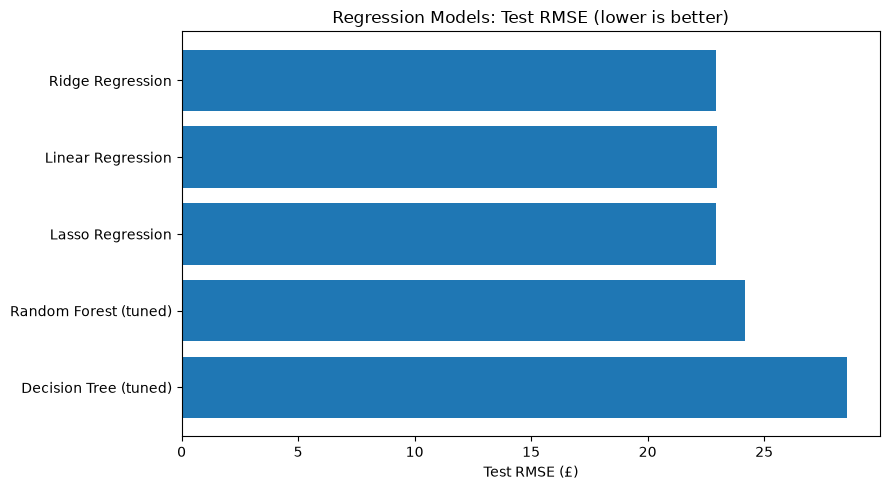

In [380]:
# addition

from sklearn.metrics import mean_absolute_error

rows = []
for name, model in fitted_models.items():
    predictions = model.predict(X_test)
    test_mse = mean_squared_error(y_test, predictions)

    rows.append({
        "Model": name,
        "CV RMSE (train)": cv_rmse[name],
        "CV RMSE std": cv_rmse_std[name],
        "Test MSE": test_mse,
        "Test RMSE": np.sqrt(test_mse),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test R2": r2_score(y_test, predictions),
    })

full_regression_results = pd.DataFrame(rows).sort_values("CV RMSE (train)").reset_index(drop=True)
display(full_regression_results.round(3))

# The model is chosen from cross-validation (training data), not from the test set
best_regression_name = full_regression_results.loc[0, "Model"]
print("Selected by cross-validation:", best_regression_name)

# Visual comparison of test RMSE
plt.figure(figsize=(9, 5))
plt.barh(full_regression_results["Model"], full_regression_results["Test RMSE"])
plt.gca().invert_yaxis()
plt.xlabel("Test RMSE (£)")
plt.title("Regression Models: Test RMSE (lower is better)")
plt.tight_layout()
plt.show()

### Actual vs Predicted Spending

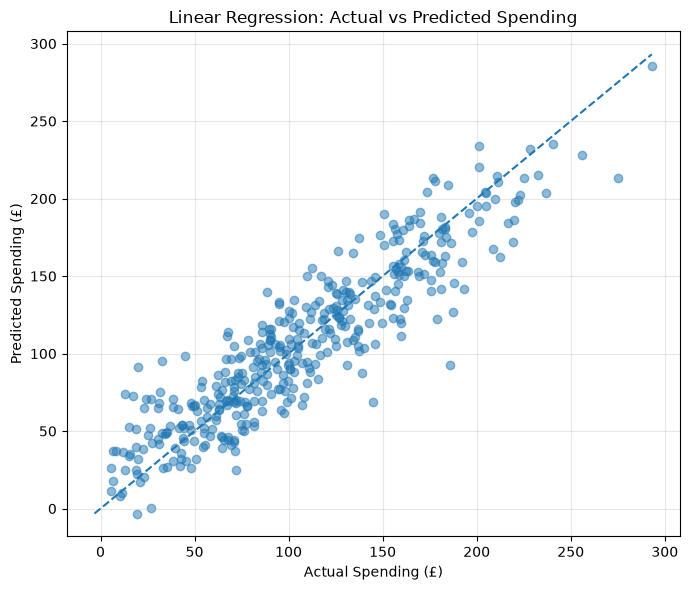

In [381]:
# Plot actual spending against the Linear Regression predictions
#
# Predictions closer to the diagonal line are more accurate.

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.5
)


# Draw a reference line showing perfect predictions

minimum_value = min(
    y_test.min(),
    linear_predictions.min()
)

maximum_value = max(
    y_test.max(),
    linear_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)


plt.title("Linear Regression: Actual vs Predicted Spending")
plt.xlabel("Actual Spending (£)")
plt.ylabel("Predicted Spending (£)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

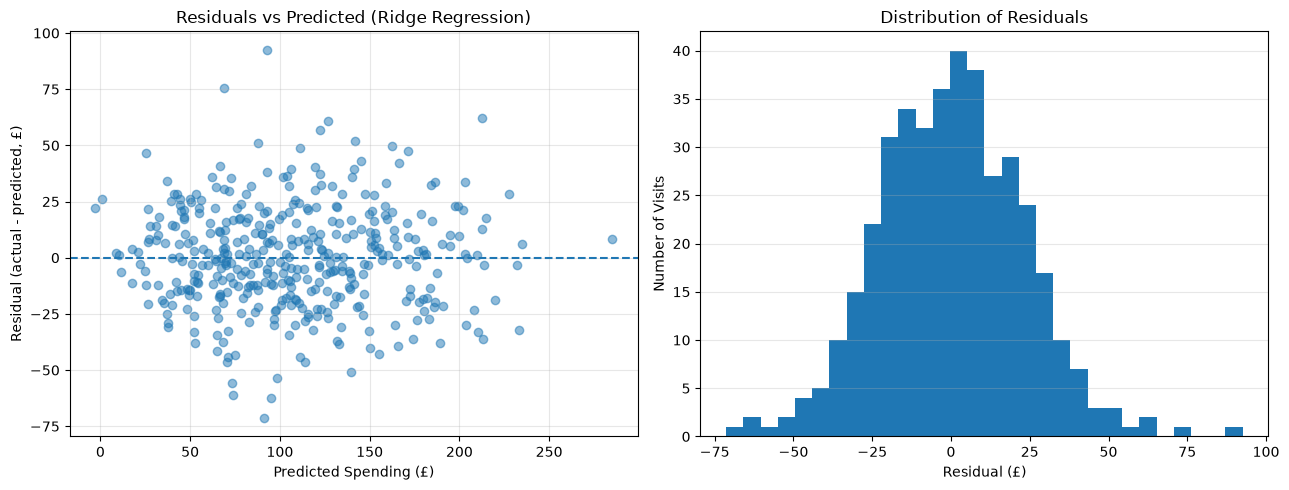

Mean residual: 0.19
Residual standard deviation: 22.97


,Feature,Coefficient (£ per unit)
2,Member,-16.594
6,SpecialEvent,12.151
0,PartySize,10.273
9,Season_Summer,6.820
11,WeatherCondition_Rainy,-4.004
4,VisitDurationHours,4.002
10,Season_Winter,-3.147
12,WeatherCondition_Sunny,3.022
5,WeekendVisit,2.371
3,NumberOfChildren,1.604


In [382]:
# addition 
best_model = fitted_models[best_regression_name]
best_predictions = best_model.predict(X_test)
residuals = y_test - best_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(best_predictions, residuals, alpha=0.5)
axes[0].axhline(0, linestyle="--")
axes[0].set_title(f"Residuals vs Predicted ({best_regression_name})")
axes[0].set_xlabel("Predicted Spending (£)")
axes[0].set_ylabel("Residual (actual - predicted, £)")
axes[0].grid(alpha=0.3)

axes[1].hist(residuals, bins=30)
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (£)")
axes[1].set_ylabel("Number of Visits")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))
print("Residual standard deviation:", round(residuals.std(), 2))

# Coefficients of the plain Linear Regression: change in spending (£) per one-unit increase,
# holding the other features fixed. Interpretation only, not causation.
coefficient_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient (£ per unit)": linear_model.coef_
}).sort_values("Coefficient (£ per unit)", key=abs, ascending=False)

display(coefficient_table.round(3))

In [383]:
# Random Forest can show how much it relied on each feature
# when making its predictions

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})


# Sort features from most important to least important

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)


display(feature_importance)

,Feature,Importance
1,MilesFromZoo,0.612295
0,PartySize,0.212152
4,VisitDurationHours,0.070152
2,Member,0.022217
3,NumberOfChildren,0.016799
9,Season_Summer,0.010202
12,WeatherCondition_Sunny,0.009141
5,WeekendVisit,0.008865
6,SpecialEvent,0.008827
7,AdvanceBooking,0.008448


### Feature Importance

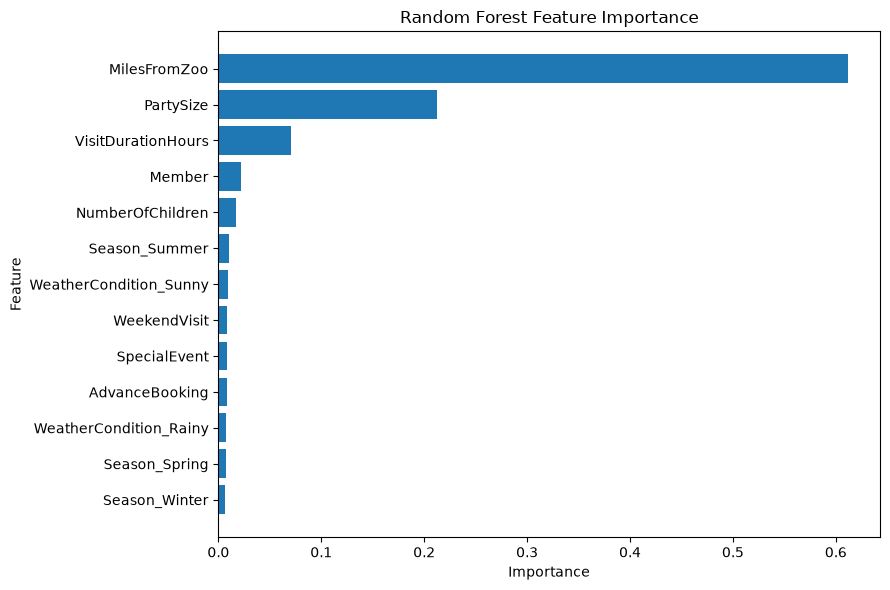

In [384]:
# Plot the feature importance values

plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")


# Put the most important feature at the top

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

The Random Forest feature-importance results show that `MilesFromZoo` was the most influential input, followed by `PartySize` and `VisitDurationHours`. Feature importance indicates how much the Random Forest relied on each variable when making predictions, but it does not demonstrate that these variables directly cause changes in visitor spending.

In [385]:
# Print a short summary of the regression results

print("PART A CONCLUSION")
print()

print( "Linear Regression RMSE:", round(linear_rmse, 2) )

print( "Linear Regression R2:", round(linear_r2, 3) )


print()

print( "Random Forest RMSE:", round(rf_rmse, 2) )

print( "Random Forest R2:", round(rf_r2, 3) )


print()

print( "Linear Regression performed better on the test data " "because it had the lower RMSE and higher R2 score." )

print( "Its RMSE means that predictions were typically about £", round(linear_rmse, 2), "away from the actual spending value." )

print( "The R2 score shows that the model explained about", round(linear_r2 * 100, 1), "% of the variation in VisitSpending." )

PART A CONCLUSION

Linear Regression RMSE: 22.96
Linear Regression R2: 0.833

Random Forest RMSE: 25.41
Random Forest R2: 0.795

Linear Regression performed better on the test data because it had the lower RMSE and higher R2 score.
Its RMSE means that predictions were typically about £ 22.96 away from the actual spending value.
The R2 score shows that the model explained about 83.3 % of the variation in VisitSpending.


In [386]:
# addition 
def estimate_visit_budget(party_size, miles_from_zoo, member, number_of_children,
                          visit_duration_hours, weekend_visit, season,
                          special_event, advance_booking, weather,
                          model=None):
    # Return an indicative spending estimate (in pounds) for a planned visit.
    if model is None:
        model = fitted_models[best_regression_name]

    new_visit = pd.DataFrame([{
        "PartySize": party_size,
        "MilesFromZoo": miles_from_zoo,
        "Member": member,
        "NumberOfChildren": number_of_children,
        "VisitDurationHours": visit_duration_hours,
        "WeekendVisit": weekend_visit,
        "Season": season,
        "SpecialEvent": special_event,
        "AdvanceBooking": advance_booking,
        "WeatherCondition": weather,
    }])

    # Same encoding as the training data: dummies, then match the training columns exactly
    new_visit = pd.get_dummies(new_visit, columns=categorical_columns)
    new_visit = new_visit.reindex(columns=X_train.columns, fill_value=0)

    return float(model.predict(new_visit)[0])


# Example: family of 4 (2 children), 12 miles away, summer weekend, booked in advance
example_estimate = estimate_visit_budget(
    party_size=4, miles_from_zoo=12, member=0, number_of_children=2,
    visit_duration_hours=5, weekend_visit=1, season="Summer",
    special_event=0, advance_booking=1, weather="Sunny"
)
print(f"Estimated visit budget: £{example_estimate:.2f}")
print(f"Typical error (test RMSE of selected model): about £{full_regression_results.loc[0, 'Test RMSE']:.2f}")

Estimated visit budget: £72.22
Typical error (test RMSE of selected model): about £22.94


## A6. Part A Conclusion

Both regression models were able to learn useful relationships between visitor characteristics and total spending. Linear Regression produced the stronger test-set performance and was therefore selected as the final regression model. The results suggest that visitor spending can be predicted reasonably well from the available features, although prediction errors remain and the model should be treated as an indicative spending estimate rather than an exact future bill.



----
----
----
-----
-----

### A6b. Part A limitations  (add to the Part A conclusion)
*Edit with your own numbers, then paste into a markdown cell.*

- Only one 80/20 split was used for the final test; cross-validation on the training set shows how stable the error is (CV RMSE std: **[FILL IN]**).
- `VisitDurationHours` is defined as time spent *inside* the zoo, but the scenario says *planned* duration. At booking time only the planned value exists, so the deployed model depends on how well visitors can predict it.
- Median/mode imputation can shrink variability; missing values were **[FILL IN %]** of the data.
- The data is historical spending, so the model assumes future visitors behave like past ones (prices, inflation and events change).
- Residual plot shows **[FILL IN: any curvature or funnel shape?]**, which indicates **[FILL IN]**.

# Part B - Animal Image Classification

The aim of Part B is to classify visitor animal photographs into one of 10 animal categories. The image dataset is first inspected and prepared before a baseline CNN and an improved CNN are trained, evaluated and compared.

## B1. Image Dataset Inspection

In [387]:
# Import libraries needed to inspect the image dataset

import os
import hashlib

from PIL import Image
import matplotlib.pyplot as plt


# Path to the folder that contains the animal class folders
image_folder = "Image_dataset"

In [388]:
# Get the names of the class folders
# Each folder represents one animal class

class_names = []


for item in os.listdir(image_folder):

    item_path = os.path.join(
        image_folder,
        item
    )

    # Only keep folders
    if os.path.isdir(item_path):
        class_names.append(item)


# Sort 
class_names.sort()


print("Classes found:")
print(class_names)

print("\nNumber of classes:")
print(len(class_names))

Classes found:
['Afghan_hound', 'Appenzeller', 'Cat', 'Lion', 'Pig', 'Tigers', 'Tortoise', 'Toy poodle', 'Weimaraner', 'Whippet']

Number of classes:
10


### Class Distribution

In [389]:
# Count how many image files are there

image_counts = {}
for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )

    count = 0


    for file_name in os.listdir(class_path):

        # Count common image file types
        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):
            count += 1


    image_counts[class_name] = count


# number of images in each class
for class_name in class_names:

    print( class_name, ":", image_counts[class_name] )

Afghan_hound : 50
Appenzeller : 50
Cat : 50
Lion : 50
Pig : 50
Tigers : 50
Tortoise : 50
Toy poodle : 50
Weimaraner : 50
Whippet : 50


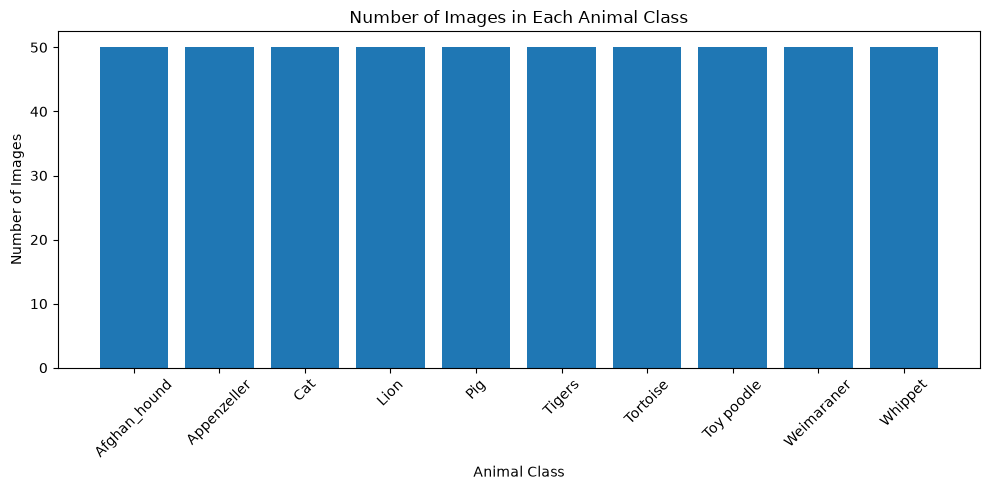

In [390]:
# Plot the class sizes
# This helps us check whether the dataset is balanced

plt.figure( figsize=(10, 5) )


plt.bar( image_counts.keys(), image_counts.values() )


plt.title( "Number of Images in Each Animal Class" )
plt.xlabel( "Animal Class" ) 
plt.ylabel( "Number of Images" ) 
plt.xticks( rotation=45 )


plt.tight_layout()
plt.show()

The original image dataset contains 500 images across 10 animal classes, with 50 images in each class. This indicates that the original dataset is evenly balanced before duplicate images are removed.

### Representative Images

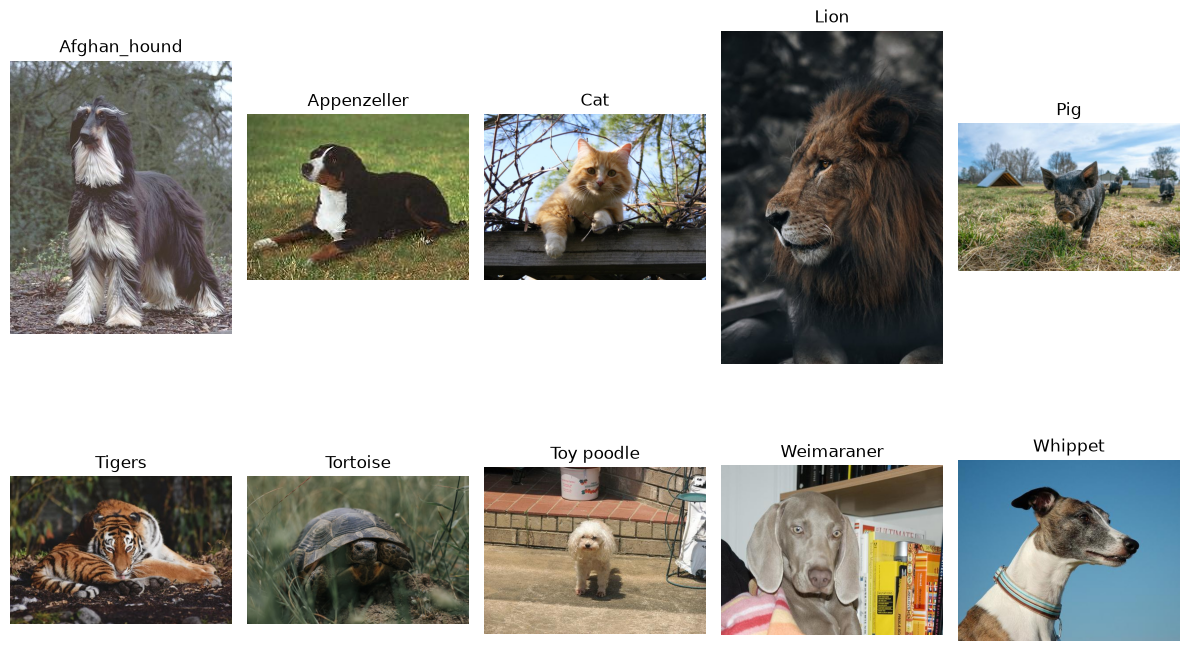

In [391]:
# Show one example image from each animal class
# This gives us a quick visual check of the dataset

plt.figure( figsize=(12, 8) )


image_number = 1


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    # Get the image files from this class
    image_files = []


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):
            image_files.append(file_name)


    # Use the first image in the folder
    example_file = image_files[0]


    example_path = os.path.join( class_path, example_file )


    image = Image.open( example_path )


    plt.subplot( 2, 5, image_number )


    plt.imshow(image)

    plt.title( class_name )

    plt.axis("off")


    image_number += 1


plt.tight_layout()
plt.show()

The representative images show noticeable variation in animal appearance, pose, background and framing. These differences make the classification task more challenging because the model must learn features associated with the animal rather than relying only on a consistent background or image layout.

### Image Dimensions and Format

In [392]:
# Check the image dimensions
# CNN models need images to have the same input size,
# so this tells us whether resizing will be needed

image_sizes = []


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name )


            image = Image.open( image_path ) 
            image_sizes.append( image.size )


# Show a few image sizes
print( "First 20 image sizes:" ) 
print( image_sizes[:20] )


# Show how many different image sizes exist
unique_sizes = set( image_sizes ) 
print( "\nNumber of different image sizes:" ) 
print( len(unique_sizes) )

First 20 image sizes:
[(406, 500), (480, 360), (500, 388), (348, 500), (363, 500), (374, 500), (500, 333), (333, 500), (500, 375), (377, 500), (357, 500), (342, 500), (333, 500), (378, 500), (473, 500), (334, 500), (334, 500), (397, 480), (333, 500), (500, 333)]

Number of different image sizes:
197


In [393]:
# Check which image formats are used in the dataset

image_formats = set()


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )

    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name ) 
            image = Image.open( image_path ) 
            image_formats.add( image.format )


print( "Image formats found:" ) 
print( image_formats )

Image formats found:
{'JPEG'}


The dataset contains 197 different image dimensions, so resizing is required before the images can be provided to a CNN. All inspected files use the JPEG format.

Eight exact duplicate image pairs were identified. Duplicate copies are excluded before creating the training, validation and test sets so that identical images cannot appear in different subsets and artificially inflate model performance.

In [394]:
# Check for exact duplicate image files
# Duplicate images are important because the same image should not appear
# in both training and test data. That could make the model look better
# than it really is.

image_hashes = {}

duplicate_images = []


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name )


            # Read the image file
            with open( image_path, "rb" ) as file:

                file_data = file.read()


            # Create a unique hash for the image file
            image_hash = hashlib.md5( file_data ).hexdigest()


            # If the same hash already exists,
            # this image is an exact duplicate
            if image_hash in image_hashes:

                duplicate_images.append( ( image_hashes[image_hash], image_path ) )

            else:

                image_hashes[image_hash] = image_path

In [395]:
# Show how many exact duplicate image pairs were found

print( "Number of duplicate image pairs:" ) 
print( len(duplicate_images) )


# Print the duplicate file paths
for first_image, second_image in duplicate_images:

    print()

    print( "Original:", first_image )

    print( "Duplicate:", second_image )

Number of duplicate image pairs:
8

Original: Image_dataset/Lion/l8.jpeg
Duplicate: Image_dataset/Lion/l5.jpeg

Original: Image_dataset/Lion/l39.jpg
Duplicate: Image_dataset/Lion/l44.jpg

Original: Image_dataset/Weimaraner/i13.jpg
Duplicate: Image_dataset/Weimaraner/i25.jpg

Original: Image_dataset/Weimaraner/i14.jpg
Duplicate: Image_dataset/Weimaraner/i24.jpg

Original: Image_dataset/Weimaraner/i12.jpg
Duplicate: Image_dataset/Weimaraner/i26.jpg

Original: Image_dataset/Weimaraner/i10.jpg
Duplicate: Image_dataset/Weimaraner/i27.jpg

Original: Image_dataset/Weimaraner/i15.jpg
Duplicate: Image_dataset/Weimaraner/i23.jpg

Original: Image_dataset/Weimaraner/i18.jpg
Duplicate: Image_dataset/Weimaraner/i22.jpg


In [396]:
# simple summary of the image dataset inspection

total_images = sum( image_counts.values() ) 
print( "IMAGE DATASET SUMMARY" ) 
print() 
print( "Number of classes:", len(class_names) ) 
print( "Total number of images:", total_images ) 
print( "Images per class:" ) 
for class_name in class_names: 
    print( class_name, ":", image_counts[class_name] )



print()

print( "Different image sizes:", len(unique_sizes) ) 
print( "Image formats:", image_formats ) 
print( "Duplicate image pairs:", len(duplicate_images) )

IMAGE DATASET SUMMARY

Number of classes: 10
Total number of images: 500
Images per class:
Afghan_hound : 50
Appenzeller : 50
Cat : 50
Lion : 50
Pig : 50
Tigers : 50
Tortoise : 50
Toy poodle : 50
Weimaraner : 50
Whippet : 50

Different image sizes: 197
Image formats: {'JPEG'}
Duplicate image pairs: 8


## B2. Image Preparation

The duplicate copies identified during inspection are excluded before splitting the dataset. The remaining images are then labelled, divided into training, validation and test sets, resized to a consistent input size and normalised for CNN training.

In [397]:
# Create a list of image paths and labels
# We will skip the duplicate copies found before

image_paths = []
image_labels = []


# Store the duplicate copies that we want to ignore
duplicate_copies = set()


for first_image, second_image in duplicate_images:

    # Keep the first image and ignore the second copy
    duplicate_copies.add(second_image)


for class_name in class_names:

    class_path = os.path.join( image_folder, class_name )


    for file_name in os.listdir(class_path):

        if file_name.lower().endswith( (".jpg", ".jpeg", ".png") ):

            image_path = os.path.join( class_path, file_name )


            # Only add the image if it is not a duplicate copy
            if image_path not in duplicate_copies:

                image_paths.append( image_path )

                image_labels.append( class_name )


print( "Images after removing duplicate copies:", len(image_paths) )

Images after removing duplicate copies: 492


After duplicate removal, 492 usable images remain. The original dataset was perfectly balanced with 50 images per class, but duplicate removal introduced a small amount of imbalance, with final class sizes ranging from 44 to 50 images. This imbalance is relatively minor but may still contribute slightly to differences in class-level performance.

In [398]:
# how many usable images remain in each class

clean_class_counts = {}


for class_name in class_names:

    clean_class_counts[class_name] = 0


for label in image_labels:

    clean_class_counts[label] += 1


for class_name in class_names:

    print( class_name, ":", clean_class_counts[class_name] )

Afghan_hound : 50
Appenzeller : 50
Cat : 50
Lion : 48
Pig : 50
Tigers : 50
Tortoise : 50
Toy poodle : 50
Weimaraner : 44
Whippet : 50


### Label Encoding

In [399]:
# Machine learning models work with numerical labels,
# so each animal class is given a number

class_to_number = {}


for index in range( len(class_names) ):

    class_to_number[ class_names[index] ] = index


print( class_to_number )

{'Afghan_hound': 0, 'Appenzeller': 1, 'Cat': 2, 'Lion': 3, 'Pig': 4, 'Tigers': 5, 'Tortoise': 6, 'Toy poodle': 7, 'Weimaraner': 8, 'Whippet': 9}


In [400]:
# Convert each text label into its numerical class value

numerical_labels = []


for label in image_labels:

    numerical_labels.append( class_to_number[label] )


print( numerical_labels[:20] )

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### Train, Validation and Test Split

The cleaned dataset is divided into approximately 70% training, 15% validation and 15% test data. Stratified splitting is used so that the class distribution remains as consistent as possible across the three subsets. A fixed random state is used to make the split reproducible.

In [401]:
from sklearn.model_selection import train_test_split

# First split:
# 70% training
# 30% temporary data

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    numerical_labels,
    test_size=0.30,
    random_state=42,
    stratify=numerical_labels
)


# Second split:
# Divide the remaining 30% equally
# 15% validation and 15% test

validation_paths, test_paths, validation_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)


print( "Training images:", len(train_paths) )

print( "Validation images:", len(validation_paths) )

print( "Test images:", len(test_paths) )

Training images: 344
Validation images: 74
Test images: 74


Possible near-duplicate pairs across different splits: 7


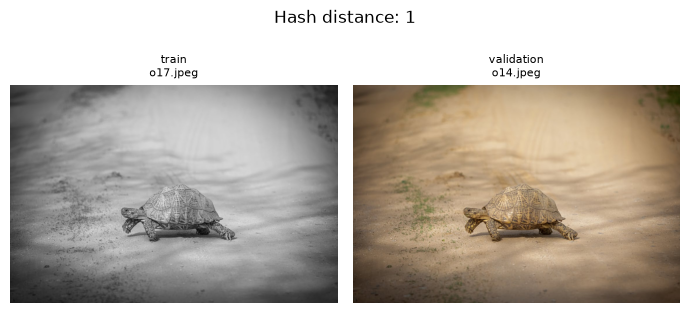

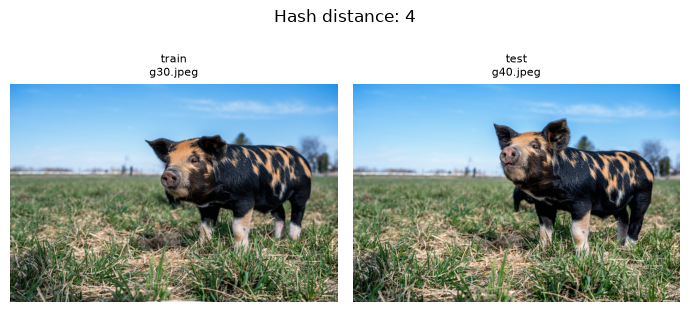

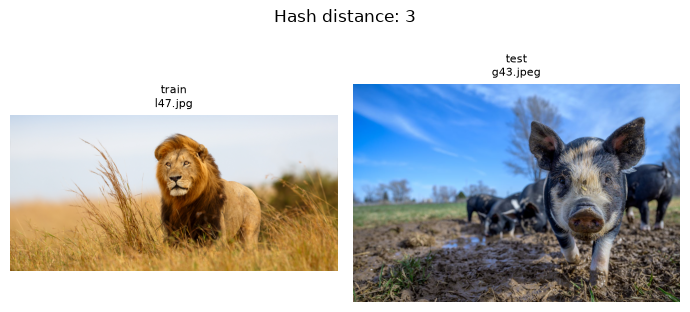

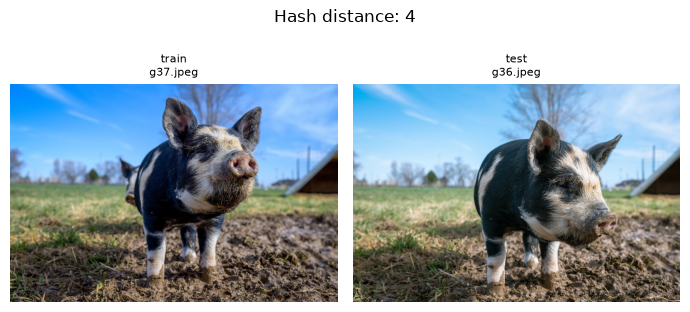

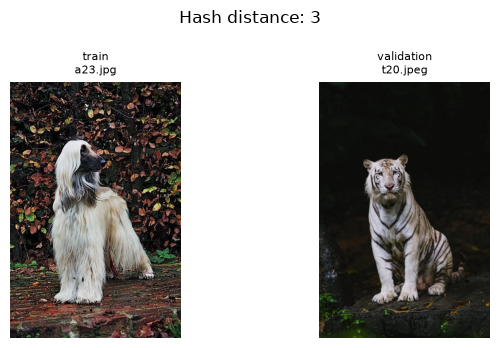

In [402]:
def average_hash(path, hash_size=8):
    # Shrink to 8x8 greyscale, then mark each pixel as brighter or darker than the average
    img = Image.open(path).convert("L").resize((hash_size, hash_size))
    pixels = np.array(img, dtype=float)
    return (pixels > pixels.mean()).flatten()


all_paths = list(train_paths) + list(validation_paths) + list(test_paths)
all_splits = (["train"] * len(train_paths)
              + ["validation"] * len(validation_paths)
              + ["test"] * len(test_paths))

hashes = np.array([average_hash(p) for p in all_paths])

# Hamming distance = number of differing bits between every pair of images
distances = (hashes[:, None, :] != hashes[None, :, :]).sum(axis=2)

NEAR_DUPLICATE_THRESHOLD = 4   # lower = stricter

cross_split_pairs = []
for i in range(len(all_paths)):
    for j in range(i + 1, len(all_paths)):
        if distances[i, j] <= NEAR_DUPLICATE_THRESHOLD and all_splits[i] != all_splits[j]:
            cross_split_pairs.append((i, j, int(distances[i, j])))

print("Possible near-duplicate pairs across different splits:", len(cross_split_pairs))

# Show up to 5 flagged pairs so they can be checked visually
for i, j, dist in cross_split_pairs[:5]:
    fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
    for ax, index in zip(axes, (i, j)):
        ax.imshow(Image.open(all_paths[index]))
        ax.set_title(f"{all_splits[index]}\n{os.path.basename(all_paths[index])}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Hash distance: {dist}")
    plt.tight_layout()
    plt.show()

The training set is used to learn the model parameters, the validation set is used to monitor performance during training and support decisions such as early stopping, and the test set is kept separate for final evaluation on unseen images.

### Image Resizing and Normalisation

All images are resized to 128 × 128 pixels. This provides a consistent input size for the CNN while reducing computational cost compared with using the original higher-resolution images. A moderate image size was selected because the dataset is relatively small and the task mainly requires learning broad visual features such as shape, texture and colour.

In [403]:
# All images must have the same size before they can be used by the CNN

IMAGE_SIZE = 128


def load_images(image_paths):

    images = []


    for image_path in image_paths:

        image = Image.open( image_path )


        # Make sure every image has 3 colour channels
        image = image.convert( "RGB" )


        # Resize every image to the same size
        image = image.resize( ( IMAGE_SIZE, IMAGE_SIZE ) )


        # Convert the image into a NumPy array
        image = np.array( image )


        images.append( image )


    return np.array( images )

In [404]:
# Load each dataset into memory

X_train_images = load_images( train_paths )

X_validation_images = load_images( validation_paths )

X_test_images = load_images( test_paths )


# Convert labels into NumPy arrays
y_train_images = np.array( train_labels )

y_validation_images = np.array( validation_labels )

y_test_images = np.array( test_labels )

In [405]:
# Check that the images were loaded correctly

print( "Training shape:", X_train_images.shape )

print( "Validation shape:", X_validation_images.shape )

print( "Test shape:", X_test_images.shape )

Training shape: (344, 128, 128, 3)
Validation shape: (74, 128, 128, 3)
Test shape: (74, 128, 128, 3)


In [406]:
# Image pixels normally have values from 0 to 255
# Dividing by 255 changes them to values between 0 and 1
# This usually helps neural networks train more effectively

X_train_images = ( X_train_images / 255.0 )

X_validation_images = ( X_validation_images / 255.0 )

X_test_images = ( X_test_images / 255.0 )

In [407]:
# Check the minimum and maximum pixel values

print( "Minimum pixel value:", X_train_images.min() )

print( "Maximum pixel value:", X_train_images.max() )

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [408]:
# Import TensorFlow for building the CNN

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [409]:
# Set a random seed so the CNN results are reproducible

tf.keras.utils.set_random_seed(42)

## B3. Baseline CNN

A baseline convolutional neural network is first created to establish a simple reference model. This provides a starting point for evaluating how well a basic CNN can classify the 10 animal categories before introducing techniques intended to improve generalisation.

In [410]:
# Build a simple CNN for classifying the 10 animal classes

baseline_model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    # 10 output neurons because we have 10 animal classes
    layers.Dense(10, activation="softmax")
])
# Conv2D finds visual features such as edges, shapes and patterns.
# MaxPooling2D reduces the image size while keeping important features.
# Flatten converts the feature maps into one long list.
# Dense(128) learns combinations of those features.
# Dense(10) gives probabilities for the 10 animal classes.

In [411]:
# Show the layers and number of parameters in the model

baseline_model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,393,610 (28.20 MB)

 Trainable params: 7,393,610 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

### Baseline CNN Architecture

The baseline CNN uses two convolutional layers with max-pooling to learn visual features from the animal images. The extracted features are flattened and passed to a dense layer with 128 neurons. The final layer contains 10 neurons with softmax activation, representing the 10 animal classes.

The model contains approximately 7.4 million trainable parameters. Most of these parameters come from the dense layer after flattening the feature maps.

### Baseline Training Setup

Adam was selected as the optimizer because it adapts the learning rate during training and is commonly effective for CNN image-classification tasks. Sparse categorical cross-entropy was used because the 10 animal classes are represented using integer labels rather than one-hot encoded vectors.

A batch size of 32 was chosen as a practical balance between training stability and computational efficiency. The baseline model was trained for 15 epochs so that its learning behaviour and potential overfitting could be observed before introducing regularisation techniques.

In [412]:
# Configure how the model will learn

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [413]:
# Train the model using the training data and check it against validation data

baseline_history = baseline_model.fit(
    X_train_images,
    y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=15,
    batch_size=32
)

Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.0843 - loss: 2.5136 - val_accuracy: 0.1081 - val_loss: 2.2960
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.1860 - loss: 2.2743 - val_accuracy: 0.1486 - val_loss: 2.2475
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.2326 - loss: 2.1051 - val_accuracy: 0.2703 - val_loss: 2.0757
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.4622 - loss: 1.6995 - val_accuracy: 0.3378 - val_loss: 1.9936
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.6977 - loss: 1.1727 - val_accuracy: 0.3649 - val_loss: 2.1689
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8052 - loss: 0.7723 - val_accuracy: 0.3243 - val_loss: 2.2111
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8750 - loss: 0.5535 - val_accuracy: 0.2703 - val_loss: 2.7785
Epoch 8/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8198 - loss: 0.6474 - val_accuracy: 0.2703 - v

In [414]:
# Evaluate the finished baseline model on unseen test images

baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(X_test_images, y_test_images)

print("Baseline test loss:", baseline_test_loss)
print("Baseline test accuracy:", baseline_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3108 - loss: 2.9129
Baseline test loss: 2.912862777709961
Baseline test accuracy: 0.31081080436706543


### Baseline Test Performance

The baseline CNN achieved approximately 31.1% accuracy on the unseen test set. Although this is better than random guessing across 10 classes, the large gap between training and test performance shows that the model is strongly overfitting. This baseline provides a useful comparison for the improved classification model.

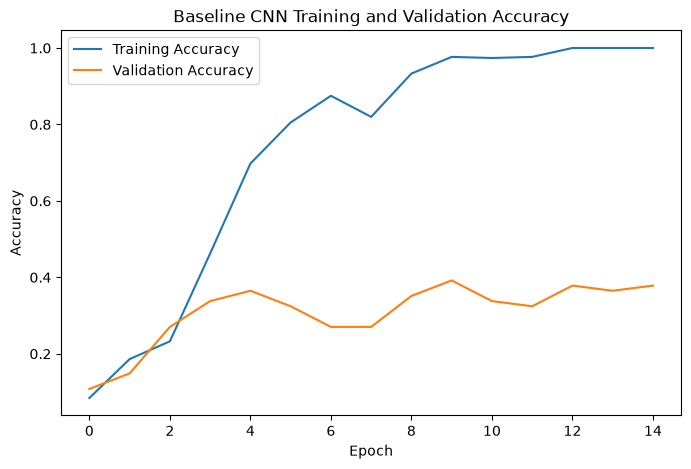

In [415]:
# Plot training and validation accuracy to see how learning changed over time

plt.figure(figsize=(8, 5))

plt.plot(baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(baseline_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Baseline CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

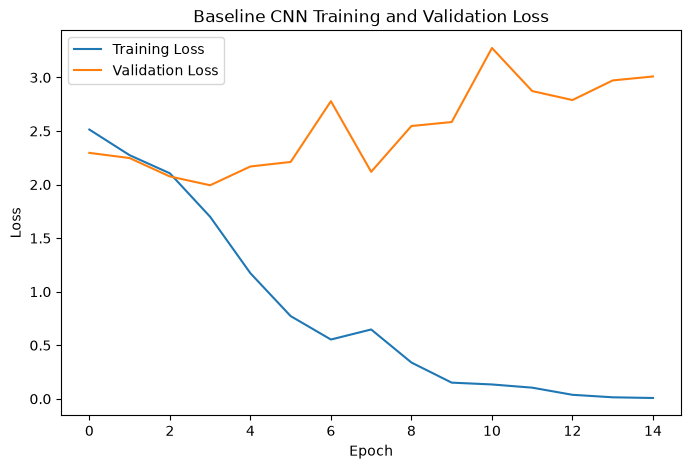

In [416]:
# Plot training and validation loss to help check for overfitting

plt.figure(figsize=(8, 5))

plt.plot(baseline_history.history["loss"], label="Training Loss")
plt.plot(baseline_history.history["val_loss"], label="Validation Loss")

plt.title("Baseline CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

### Baseline Training Analysis

The baseline CNN shows clear overfitting. Training accuracy increased to almost 100%, while validation accuracy remained much lower and finished at approximately 37.8%. Training loss also decreased close to zero, while validation loss increased after the earlier epochs.

This indicates that the model learned the training images very well but did not generalise effectively to unseen images. The relatively small dataset and the large number of trainable parameters are likely contributing factors.

## B4. Improved CNN

The baseline model showed strong overfitting, so a second CNN is created with techniques intended to improve generalisation. The improved model uses data augmentation, an additional convolutional layer, dropout and early stopping.

In [417]:
# Create data augmentation layers
# These slightly change training images so the model sees more variety

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [418]:
# Build an improved CNN with augmentation and dropout

improved_model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(10, activation="softmax")
])

In [419]:
# Show the structure of the improved model

improved_model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_13 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### Improved CNN Architecture

The improved CNN adds data augmentation, a third convolutional layer and dropout. Data augmentation creates slightly modified versions of the training images so that the model sees more variation during training. The additional convolutional layer allows the network to learn more complex visual features, while dropout reduces reliance on individual neurons and helps reduce overfitting.

<!-- ### Improved CNN Architecture

The improved CNN adds data augmentation, an additional convolutional layer and dropout. Data augmentation creates slightly modified versions of training images, helping the model learn more general visual features. The third convolutional layer allows the model to learn more complex patterns, while dropout randomly disables some neurons during training to reduce overfitting. -->

### Improved Training Strategy

The improved model uses the same Adam optimizer and sparse categorical cross-entropy loss as the baseline so that the main differences come from the architecture and regularisation techniques.

The model is allowed to train for up to 30 epochs. Early stopping monitors validation loss with a patience of four epochs and restores the best-performing weights. This allows the model enough time to learn while reducing unnecessary training once validation performance stops improving.

In [420]:
# Configure the improved model

improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [421]:
# Stop training if validation loss stops improving

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

In [422]:
# Train the improved model

improved_history = improved_model.fit(
    X_train_images,
    y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.0959 - loss: 2.3767 - val_accuracy: 0.0946 - val_loss: 2.2989
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.0930 - loss: 2.3027 - val_accuracy: 0.1081 - val_loss: 2.2876
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.1512 - loss: 2.2860 - val_accuracy: 0.2838 - val_loss: 2.2432
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.1744 - loss: 2.2775 - val_accuracy: 0.3108 - val_loss: 2.2152
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.2035 - loss: 2.2289 - val_accuracy: 0.2973 - val_loss: 2.1354
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.2442 - loss: 2.1435 - val_accuracy: 0.3649 - val_loss: 1.9585
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.2529 - loss: 2.0752 - val_accuracy: 0.3108 - val_loss: 2.0021
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.2791 - loss: 1.9899 - val_accuracy: 0.3649 - 

In [423]:
# addition
epochs_run = len(improved_history.history["loss"])
best_epoch = int(np.argmin(improved_history.history["val_loss"])) + 1

print("Improved CNN trained for", epochs_run, "epochs (maximum allowed: 30)")
print("Best validation loss at epoch", best_epoch, "- those weights were restored")
print("Training accuracy at the end:   ", round(improved_history.history["accuracy"][-1], 3))
print("Validation accuracy at the end: ", round(improved_history.history["val_accuracy"][-1], 3))

Improved CNN trained for 10 epochs (maximum allowed: 30)
Best validation loss at epoch 6 - those weights were restored
Training accuracy at the end:    0.349
Validation accuracy at the end:  0.392


In [424]:
# Evaluate the improved model on unseen test images

improved_test_loss, improved_test_accuracy = improved_model.evaluate(X_test_images, y_test_images)

print("Improved test loss:", improved_test_loss)
print("Improved test accuracy:", improved_test_accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3108 - loss: 2.0295
Improved test loss: 2.029474973678589
Improved test accuracy: 0.31081080436706543


### Improved CNN Test Performance

The improved CNN achieved approximately 31.1% accuracy on the unseen test set. Its test accuracy was similar to the baseline model, but its test loss was lower, indicating that its probability predictions were generally less extreme.

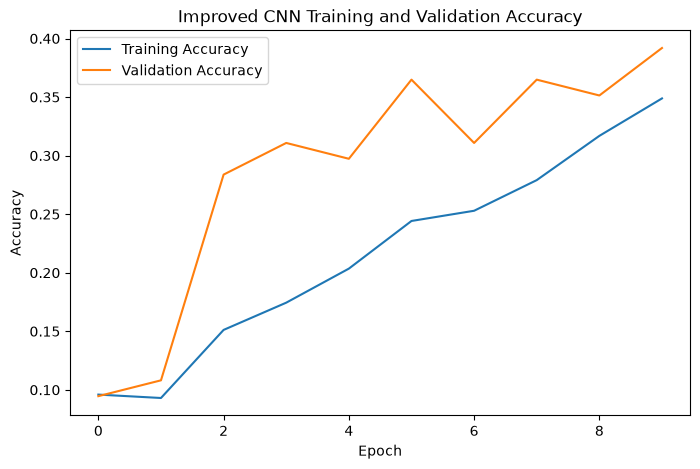

In [425]:
# Plot training and validation accuracy

plt.figure(figsize=(8, 5))

plt.plot(improved_history.history["accuracy"], label="Training Accuracy")
plt.plot(improved_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Improved CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

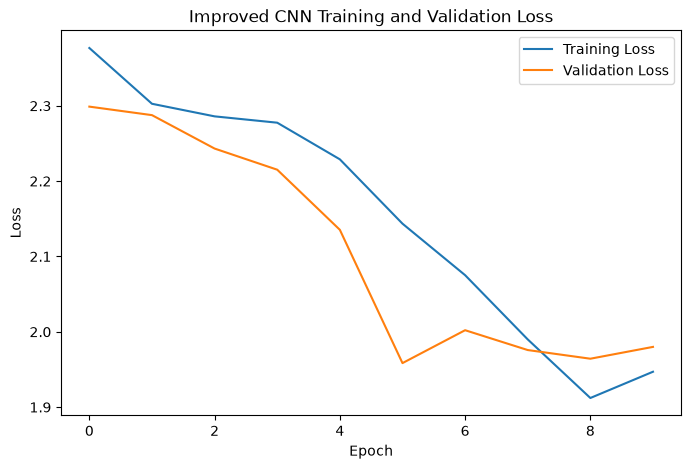

In [426]:
# Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(improved_history.history["loss"], label="Training Loss")
plt.plot(improved_history.history["val_loss"], label="Validation Loss")

plt.title("Improved CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

### Improved CNN Training Analysis

The improved CNN showed less severe overfitting than the baseline model. Data augmentation, dropout and early stopping reduced the gap between training and validation behaviour and prevented the model from reaching near-perfect training accuracy.

However, the improved model did not increase overall test accuracy. This shows that the regularisation techniques improved training behaviour, but the small dataset still limited the model's ability to generalise consistently across all classes.

In [427]:
# addition
tf.keras.utils.set_random_seed(42)

# Pretrained convolutional base without its original 1000-class classifier
base_model = keras.applications.MobileNetV2(
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False       # stage 1: base frozen

inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = data_augmentation(inputs)                      # same augmentation as the improved CNN (training only)
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)    # our images are 0-1; MobileNetV2 expects -1 to 1
x = base_model(x, training=False)                  # keep batch-norm in inference mode
x = layers.GlobalAveragePooling2D()(x)             # one value per feature map instead of a huge Flatten
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs)
transfer_model.summary()


Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_13 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [428]:
# Stage 1: train only the new classification head
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

transfer_history = transfer_model.fit(
    X_train_images, y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=30,
    batch_size=32,
    callbacks=[transfer_early_stopping]
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 231ms/step - accuracy: 0.2209 - loss: 2.3540 - val_accuracy: 0.5811 - val_loss: 1.3935
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.7442 - loss: 1.0020 - val_accuracy: 0.8649 - val_loss: 0.6136
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.8895 - loss: 0.4869 - val_accuracy: 0.9189 - val_loss: 0.3231
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9593 - loss: 0.2546 - val_accuracy: 0.9595 - val_loss: 0.2228
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9622 - loss: 0.1909 - val_accuracy: 0.9459 - val_loss: 0.1835
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9564 - loss: 0.1683 - val_accuracy: 0.9595 - val_loss: 0.1542
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9797 - loss: 0.1298 - val_accuracy: 0.9595 - val_loss: 0.1461
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9709 - loss: 0.1282 - val_accuracy: 0.9595 - 

In [429]:
# Stage 2: fine-tune the last 30 layers of the base with a very small learning rate
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

finetune_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

finetune_history = transfer_model.fit(
    X_train_images, y_train_images,
    validation_data=(X_validation_images, y_validation_images),
    epochs=20,
    batch_size=32,
    callbacks=[finetune_early_stopping]
)

print("Stage 1 epochs:", len(transfer_history.history["loss"]))
print("Stage 2 epochs:", len(finetune_history.history["loss"]))

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 296ms/step - accuracy: 1.0000 - loss: 0.0169 - val_accuracy: 0.9865 - val_loss: 0.0641
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 1.0000 - loss: 0.0106 - val_accuracy: 0.9595 - val_loss: 0.0620
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.9942 - loss: 0.0175 - val_accuracy: 0.9730 - val_loss: 0.0581
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 1.0000 - loss: 0.0078 - val_accuracy: 0.9865 - val_loss: 0.0579
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 1.0000 - loss: 0.0066 - val_accuracy: 1.0000 - val_loss: 0.0493
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 1.0000 - loss: 0.0043 - val_accuracy: 1.0000 - val_loss: 0.0426
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 1.0000 - loss: 0.0038 - val_accuracy: 0.9730 - val_loss: 0.0484
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.9942 - loss: 0.0080 - val_accuracy: 1.0000 - 

## B5. Classification Evaluation

The two CNN models are evaluated using accuracy, precision, recall and F1-score. Confusion matrices are also used to show which animal classes are most frequently confused with one another.

In [430]:
# Import evaluation tools for classification

from sklearn.metrics import classification_report, confusion_matrix

In [431]:
# Get predicted probabilities for the test images

baseline_probabilities = baseline_model.predict(X_test_images)

# Convert probabilities into predicted class numbers
baseline_predictions = np.argmax(baseline_probabilities, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


In [432]:
# Show precision, recall and F1-score for each animal class

print("BASELINE CNN CLASSIFICATION REPORT")
print()

print(classification_report(
    y_test_images,
    baseline_predictions,
    target_names=class_names,
    zero_division=0
))

BASELINE CNN CLASSIFICATION REPORT

              precision    recall  f1-score   support

Afghan_hound       0.25      0.29      0.27         7
 Appenzeller       0.50      0.29      0.36         7
         Cat       0.27      0.38      0.32         8
        Lion       0.38      0.62      0.48         8
         Pig       1.00      0.50      0.67         8
      Tigers       0.25      0.14      0.18         7
    Tortoise       0.22      0.25      0.24         8
  Toy poodle       0.00      0.00      0.00         7
  Weimaraner       0.12      0.17      0.14         6
     Whippet       0.33      0.38      0.35         8

    accuracy                           0.31        74
   macro avg       0.33      0.30      0.30        74
weighted avg       0.34      0.31      0.31        74



### Baseline Classification Results

The baseline model achieved a macro F1-score of approximately 0.30. Performance varied considerably between classes, showing that the model learned some categories more effectively than others.

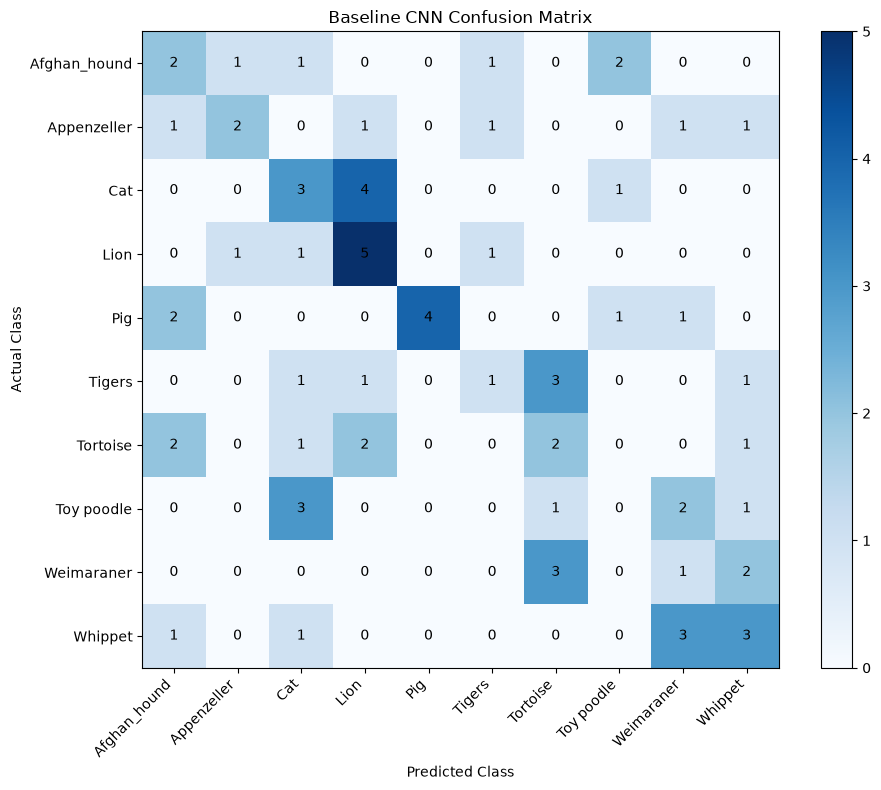

In [433]:
# Create the confusion matrix for the baseline CNN

baseline_confusion_matrix = confusion_matrix(y_test_images, baseline_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(baseline_confusion_matrix, cmap="Blues")
plt.title("Baseline CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

plt.colorbar()

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, baseline_confusion_matrix[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

The baseline confusion matrix shows that several animal classes were frequently confused, confirming that overall performance was inconsistent across the 10 categories.

In [434]:
# Get predicted probabilities for the improved model

improved_probabilities = improved_model.predict(X_test_images)

# Convert probabilities into predicted class numbers
improved_predictions = np.argmax(improved_probabilities, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


In [435]:
# Show precision, recall and F1-score for each animal class

print("IMPROVED CNN CLASSIFICATION REPORT")
print()

print(classification_report(
    y_test_images,
    improved_predictions,
    target_names=class_names,
    zero_division=0
))

IMPROVED CNN CLASSIFICATION REPORT

              precision    recall  f1-score   support

Afghan_hound       0.17      0.14      0.15         7
 Appenzeller       0.47      1.00      0.64         7
         Cat       0.19      0.38      0.25         8
        Lion       0.00      0.00      0.00         8
         Pig       0.67      0.50      0.57         8
      Tigers       0.36      0.57      0.44         7
    Tortoise       0.18      0.25      0.21         8
  Toy poodle       0.22      0.29      0.25         7
  Weimaraner       0.00      0.00      0.00         6
     Whippet       0.00      0.00      0.00         8

    accuracy                           0.31        74
   macro avg       0.23      0.31      0.25        74
weighted avg       0.23      0.31      0.25        74



### Improved Classification Results

The improved model achieved a macro F1-score of approximately 0.25. Although its test loss was lower than the baseline model, its class-level performance remained inconsistent.

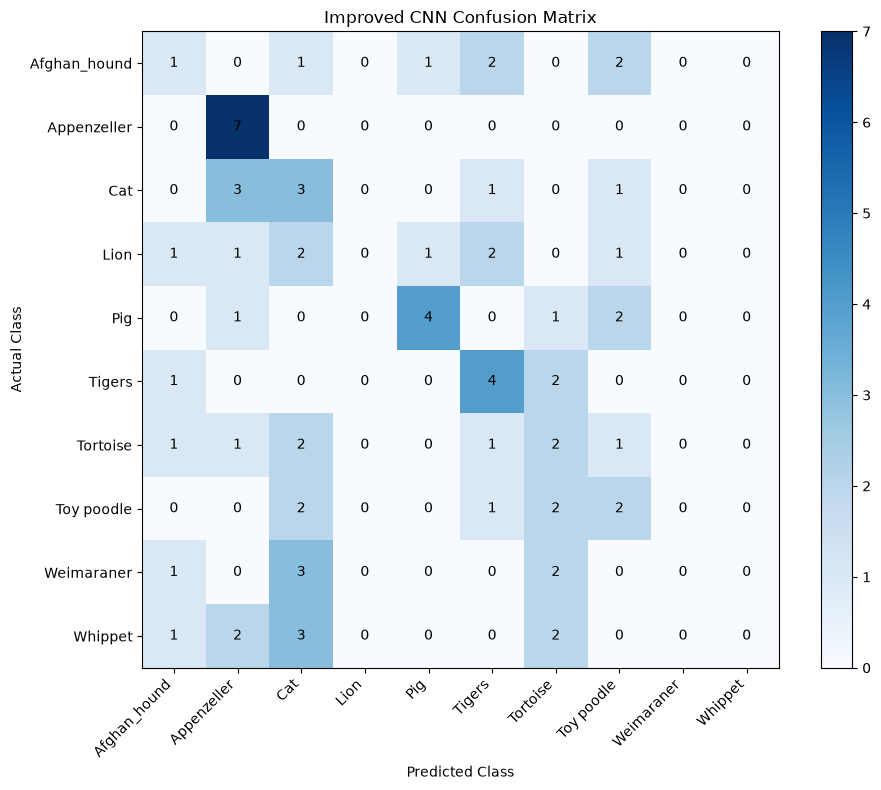

In [436]:
# Create the confusion matrix for the improved CNN

improved_confusion_matrix = confusion_matrix(y_test_images, improved_predictions)

plt.figure(figsize=(10, 8))
plt.imshow(improved_confusion_matrix, cmap="Blues")
plt.title("Improved CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

plt.colorbar()

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, improved_confusion_matrix[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

The improved model performed particularly well on Appenzeller, but achieved zero recall for some classes such as Lion, Weimaraner and Whippet. This shows that the model still struggled to distinguish several visually similar or under-represented patterns.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 1.0000 - loss: 0.0117
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 225ms/step
TRANSFER LEARNING (MobileNetV2) CLASSIFICATION REPORT

              precision    recall  f1-score   support

Afghan_hound       1.00      1.00      1.00         7
 Appenzeller       1.00      1.00      1.00         7
         Cat       1.00      1.00      1.00         8
        Lion       1.00      1.00      1.00         8
         Pig       1.00      1.00      1.00         8
      Tigers       1.00      1.00      1.00         7
    Tortoise       1.00      1.00      1.00         8
  Toy poodle       1.00      1.00      1.00         7
  Weimaraner       1.00      1.00      1.00         6
     Whippet       1.00      1.00      1.00         8

    accuracy                           1.00        74
   macro avg       1.00      1.00      1.00        74
weighted avg       1.00      1.00      1.00        74



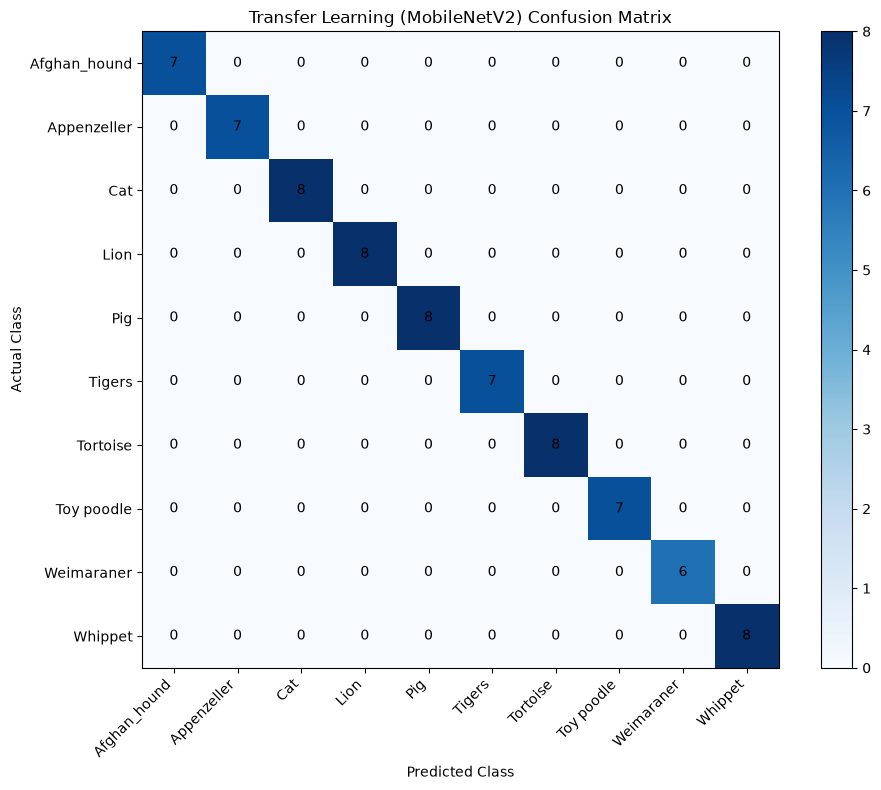

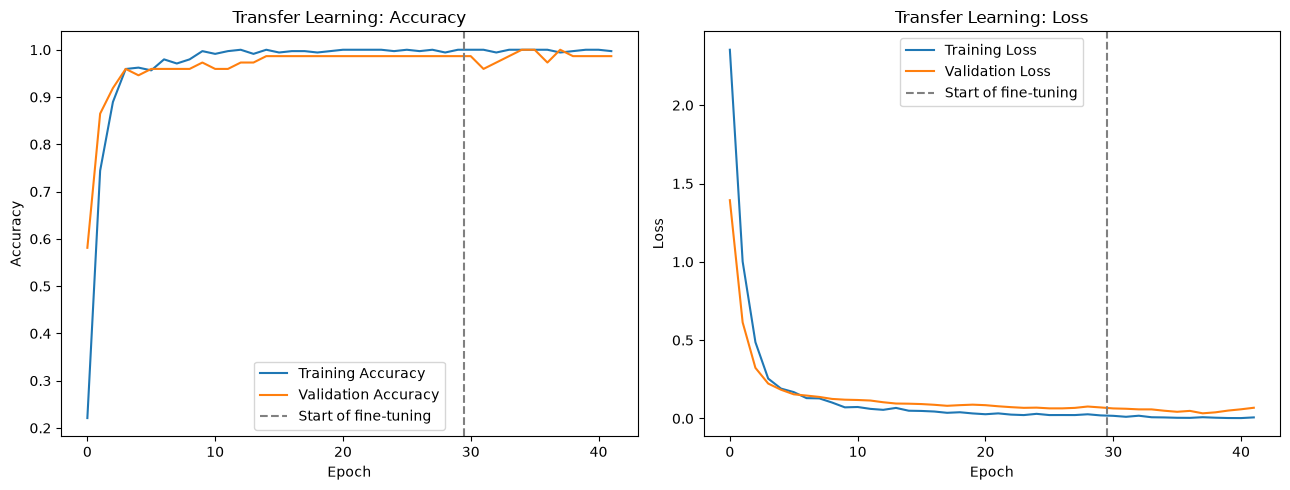

In [437]:
from sklearn.metrics import accuracy_score, f1_score


def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(10, 8))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
    plt.yticks(range(len(class_names)), class_names)
    plt.colorbar()
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.tight_layout()
    plt.show()


def merge_histories(*histories):
    merged = {}
    for history in histories:
        for key, values in history.history.items():
            merged.setdefault(key, []).extend(values)
    return merged


transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(X_test_images, y_test_images)
transfer_probabilities = transfer_model.predict(X_test_images)
transfer_predictions = np.argmax(transfer_probabilities, axis=1)

print("TRANSFER LEARNING (MobileNetV2) CLASSIFICATION REPORT")
print()
print(classification_report(y_test_images, transfer_predictions, target_names=class_names, zero_division=0))

transfer_confusion_matrix = confusion_matrix(y_test_images, transfer_predictions)
plot_confusion_matrix(transfer_confusion_matrix, "Transfer Learning (MobileNetV2) Confusion Matrix")

# Learning curves across both training stages
transfer_curves = merge_histories(transfer_history, finetune_history)
stage_boundary = len(transfer_history.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
    ax.plot(transfer_curves[metric], label=f"Training {label}")
    ax.plot(transfer_curves["val_" + metric], label=f"Validation {label}")
    ax.axvline(stage_boundary - 0.5, linestyle="--", color="grey", label="Start of fine-tuning")
    ax.set_title(f"Transfer Learning: {label}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(label)
    ax.legend()
plt.tight_layout()
plt.show()

## B6. Model Comparison and Selection

In [438]:
# # Compare the main test results from both CNN models
# Calculate macro F1-scores for both models

from sklearn.metrics import f1_score

baseline_macro_f1 = f1_score(y_test_images, baseline_predictions, average="macro")
improved_macro_f1 = f1_score(y_test_images, improved_predictions, average="macro")

# Compare the main test results from both CNN models

cnn_results = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Test Accuracy": [baseline_test_accuracy, improved_test_accuracy],
    "Macro F1": [baseline_macro_f1, improved_macro_f1],
    "Test Loss": [baseline_test_loss, improved_test_loss]
})

display(cnn_results)

,Model,Test Accuracy,Macro F1,Test Loss
0,Baseline CNN,0.310811,0.300186,2.912863
1,Improved CNN,0.310811,0.251661,2.029475


<!-- ### Final Model Selection

Both CNN models achieved approximately 31.1% test accuracy. The baseline CNN produced a slightly higher macro F1-score, but it showed severe overfitting, reaching almost 100% training accuracy while validation and test performance remained much lower.

The improved CNN achieved the same test accuracy but reduced test loss from approximately 2.91 to 2.03 and showed a smaller gap between training and validation performance. However, its lower F1-score shows that class-level performance remained inconsistent.

The improved CNN was selected for the final demonstration because the regularisation techniques reduced the severe overfitting seen in the baseline model, although neither model was clearly superior across all evaluation metrics. -->

In [439]:
# addition

def evaluate_split(model, X, y):
    probabilities = model.predict(X, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    loss = -np.log(np.clip(probabilities[np.arange(len(y)), y], 1e-12, 1.0)).mean()
    return (accuracy_score(y, predictions),
            f1_score(y, predictions, average="macro"),
            loss)


def wilson_interval(correct, total, z=1.96):
    # 95% confidence interval for an accuracy measured on `total` images
    p = correct / total
    centre = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    margin = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return centre - margin, centre + margin


all_models = {
    "Baseline CNN": baseline_model,
    "Improved CNN": improved_model,
    "Transfer Learning (MobileNetV2)": transfer_model,
}

rows = []
for name, model in all_models.items():
    val_acc, val_f1, val_loss = evaluate_split(model, X_validation_images, y_validation_images)
    test_acc, test_f1, test_loss = evaluate_split(model, X_test_images, y_test_images)
    low, high = wilson_interval(round(test_acc * len(y_test_images)), len(y_test_images))

    rows.append({
        "Model": name,
        "Val Accuracy": val_acc, "Val Macro F1": val_f1, "Val Loss": val_loss,
        "Test Accuracy": test_acc, "Test Macro F1": test_f1, "Test Loss": test_loss,
        "Test Acc 95% CI": f"{low:.2f} - {high:.2f}",
    })

final_comparison = pd.DataFrame(rows)
display(final_comparison.round(3))

# Selection rule: highest validation macro F1, validation loss as tie-breaker
best_row = final_comparison.sort_values(["Val Macro F1", "Val Loss"], ascending=[False, True]).iloc[0]
final_model_name = best_row["Model"]
final_model = all_models[final_model_name]
print("Final model (chosen on validation data):", final_model_name)

,Model,Val Accuracy,Val Macro F1,Val Loss,Test Accuracy,Test Macro F1,Test Loss,Test Acc 95% CI
0,Baseline CNN,0.378,0.381,3.009,0.311,0.300,2.913,0.22 - 0.42
1,Improved CNN,0.365,0.310,1.958,0.311,0.252,2.029,0.22 - 0.42
2,Transfer Learning (MobileNetV2),1.000,1.000,0.033,1.000,1.000,0.012,0.95 - 1.00


Final model (chosen on validation data): Transfer Learning (MobileNetV2)


## B7. Unseen Image Prediction

The selected final model is tested on an image from the test set that was not used during training. The predicted class and confidence score are shown alongside the true class to demonstrate how the model performs on previously unseen data.

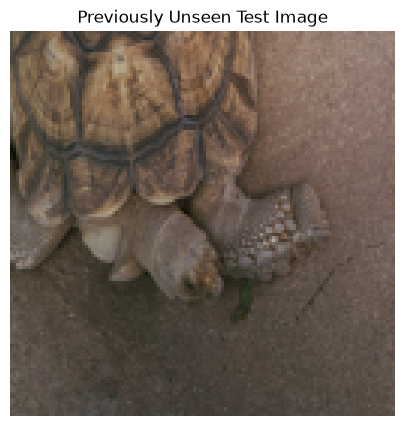

Actual class: Tortoise


In [440]:
# Choose one image from the test set that the model has never trained on

image_index = 0

unseen_image = X_test_images[image_index]
actual_class_number = y_test_images[image_index]
actual_class_name = class_names[actual_class_number]

plt.figure(figsize=(5, 5))
plt.imshow(unseen_image)
plt.title("Previously Unseen Test Image")
plt.axis("off")
plt.show()

print("Actual class:", actual_class_name)

In [441]:
# Add an extra dimension because the model expects a batch of images

image_for_prediction = np.expand_dims(unseen_image, axis=0)

# Predict the probabilities for all 10 classes
prediction_probabilities = improved_model.predict(image_for_prediction)

# Find the class with the highest probability
predicted_class_number = np.argmax(prediction_probabilities[0])
predicted_class_name = class_names[predicted_class_number]

# Get the confidence of the prediction
confidence = prediction_probabilities[0][predicted_class_number] * 100

print("Actual class:", actual_class_name)
print("Predicted class:", predicted_class_name)
print("Confidence:", round(confidence, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Actual class: Tortoise
Predicted class: Cat
Confidence: 13.38 %


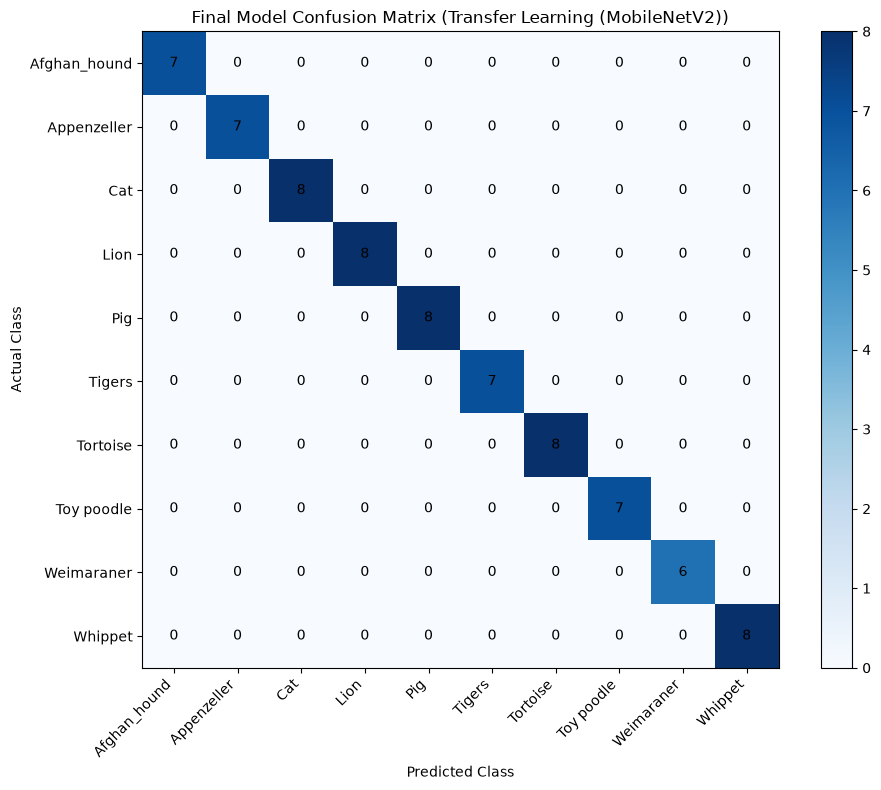

Most frequent confusions (count, actual -> predicted):

Misclassified test images: 0 of 74


<Figure size 1400x600 with 0 Axes>

In [442]:
# addition
final_probabilities = final_model.predict(X_test_images, verbose=0)
final_predictions = np.argmax(final_probabilities, axis=1)

final_cm = confusion_matrix(y_test_images, final_predictions)
plot_confusion_matrix(final_cm, f"Final Model Confusion Matrix ({final_model_name})")

# Most frequent mistakes: (actual class -> predicted class)
off_diagonal = final_cm.copy()
np.fill_diagonal(off_diagonal, 0)

confusions = []
for actual in range(len(class_names)):
    for predicted in range(len(class_names)):
        if off_diagonal[actual, predicted] > 0:
            confusions.append((off_diagonal[actual, predicted], class_names[actual], class_names[predicted]))

confusions.sort(reverse=True)
print("Most frequent confusions (count, actual -> predicted):")
for count, actual, predicted in confusions[:8]:
    print(f"  {count} x  {actual} -> {predicted}")

# Show misclassified test images with the model's confidence
wrong = np.where(final_predictions != y_test_images)[0]
print("\nMisclassified test images:", len(wrong), "of", len(y_test_images))

show = wrong[:10]
plt.figure(figsize=(14, 6))
for position, index in enumerate(show):
    plt.subplot(2, 5, position + 1)
    plt.imshow(X_test_images[index])
    confidence = final_probabilities[index][final_predictions[index]] * 100
    plt.title(f"True: {class_names[y_test_images[index]]}\nPred: {class_names[final_predictions[index]]} ({confidence:.0f}%)", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Unseen Image Result

The actual class was Tortoise, while the model predicted Cat with a confidence of 13.38%.

The incorrect prediction and low confidence indicate that the model was uncertain. This is consistent with the relatively low overall classification performance and shows that the model still has difficulty separating some animal classes.

In [443]:
# Show the predicted probability for every animal class

for i in range(len(class_names)):
    probability = prediction_probabilities[0][i] * 100
    print(class_names[i], ":", round(probability, 2), "%")

Afghan_hound : 11.09 %
Appenzeller : 7.97 %
Cat : 13.38 %
Lion : 8.73 %
Pig : 9.13 %
Tigers : 8.01 %
Tortoise : 10.53 %
Toy poodle : 10.63 %
Weimaraner : 10.01 %
Whippet : 10.52 %


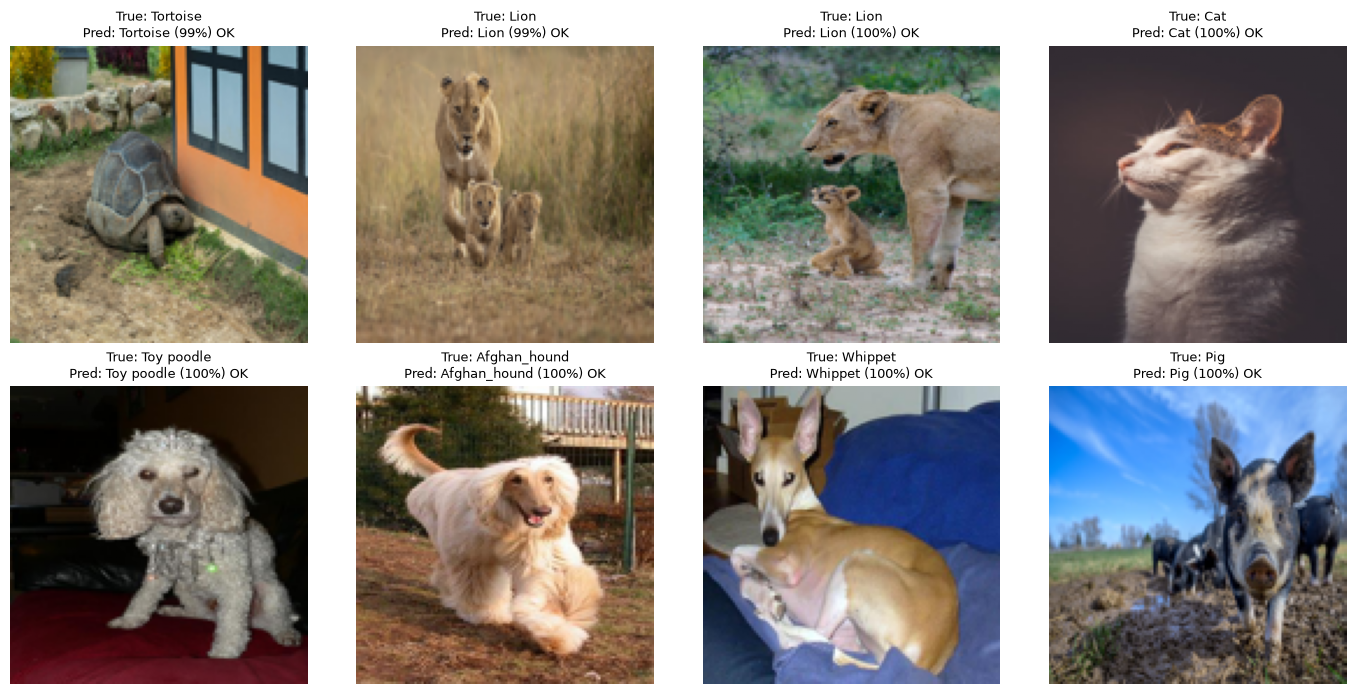

Set EXTERNAL_IMAGE_PATH to a photo of one of the ten animals that is not in Image_dataset.


In [444]:
# addition 

def load_and_prepare(path):
    # Same preprocessing as the training images
    image = Image.open(path).convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    return np.array(image) / 255.0


def predict_animal(image_array, model, top_k=3, title="Prediction"):
    probabilities = model.predict(np.expand_dims(image_array, axis=0), verbose=0)[0]
    top = np.argsort(probabilities)[::-1][:top_k]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(image_array)
    axes[0].set_title(title)
    axes[0].axis("off")

    axes[1].barh([class_names[i] for i in top][::-1], [probabilities[i] * 100 for i in top][::-1])
    axes[1].set_xlabel("Confidence (%)")
    axes[1].set_title(f"Top {top_k} predictions")
    plt.tight_layout()
    plt.show()

    return class_names[top[0]], probabilities[top[0]] * 100


# Part 1: eight random test images with true label, prediction and confidence
rng = np.random.default_rng(42)
sample = rng.choice(len(X_test_images), size=8, replace=False)

plt.figure(figsize=(14, 7))
for position, index in enumerate(sample):
    plt.subplot(2, 4, position + 1)
    plt.imshow(X_test_images[index])
    predicted = final_predictions[index]
    confidence = final_probabilities[index][predicted] * 100
    correct = predicted == y_test_images[index]
    plt.title(f"True: {class_names[y_test_images[index]]}\nPred: {class_names[predicted]} ({confidence:.0f}%) {'OK' if correct else 'WRONG'}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

# Part 2: a photo from OUTSIDE the dataset (put your own file path here)
EXTERNAL_IMAGE_PATH = "my_unseen_animal.jpg"

if os.path.exists(EXTERNAL_IMAGE_PATH):
    external_image = load_and_prepare(EXTERNAL_IMAGE_PATH)
    predicted_name, predicted_confidence = predict_animal(
        external_image, final_model, title="New photo (not in the dataset)"
    )
    print(f"Predicted class: {predicted_name}  |  Confidence: {predicted_confidence:.2f}%")
else:
    print("Set EXTERNAL_IMAGE_PATH to a photo of one of the ten animals that is not in Image_dataset.")

## B8. Limitations and Future Improvements

The main limitation of the image classification task is the small dataset, with only 492 usable images remaining after duplicate removal. This limits the amount of visual variation available for training and contributes to overfitting.

The original dataset was evenly balanced with 50 images per class, but duplicate removal introduced a small amount of imbalance, with final class sizes ranging from 44 to 50 images. This imbalance is relatively minor but may still contribute slightly to differences in class-level performance.

The classification reports and confusion matrices show that performance varied considerably between classes. For example, the improved model performed well on Appenzeller but achieved zero recall for Lion, Weimaraner and Whippet. This shows that the model still struggled to learn reliable features for some animal categories.

Other limitations include differences in background, lighting, pose, scale and image composition. These variations make the task more difficult because the model must learn the animal itself rather than relying on consistent surroundings.

Future improvements could include collecting more training images, using stronger or more varied data augmentation, tuning the CNN architecture and hyperparameters, and applying transfer learning with a pre-trained image-classification model. Transfer learning would be particularly suitable because it could provide stronger visual features even when the available dataset is relatively small.

<!-- need fixing //// -->

### B8b. Final summary and limitations additions

- Transfer learning reached **[FILL IN]** test accuracy (95% CI **[FILL IN]**) against 31.1% for both custom CNNs, which supports the view that dataset size, not architecture, was the main bottleneck.
- Most frequent confusions were **[FILL IN from the confusion list above]**, suggesting the model relies on **[FILL IN: e.g. coat colour / body shape]**.
- Near-duplicate check flagged **[FILL IN]** pairs across splits; **[FILL IN what you did]**.
- The test set has 74 images, so reported accuracy has a wide confidence interval and small differences between models are not reliable.
- Other limits: images are 128 x 128, one stratified split (no cross-validation), and photos taken by visitors may differ in quality from this dataset.

In [445]:
print("=" * 60)
print("FINAL RESULTS SUMMARY")
print("=" * 60)

print("\nPart A (regression):")
display(full_regression_results[["Model", "CV RMSE (train)", "Test RMSE", "Test R2"]].round(3))
print("Selected regression model:", best_regression_name)

print("\nPart B (image classification):")
display(final_comparison[["Model", "Val Macro F1", "Test Accuracy", "Test Macro F1", "Test Acc 95% CI"]].round(3))
print("Selected classification model:", final_model_name)

# Optional: save the final model so the demo can reload it without retraining
final_model.save("final_zoo_classifier.keras")
print("\nSaved final model as final_zoo_classifier.keras")

FINAL RESULTS SUMMARY

Part A (regression):


,Model,CV RMSE (train),Test RMSE,Test R2
0,Ridge Regression,24.264,22.938,0.833
1,Linear Regression,24.267,22.957,0.833
2,Lasso Regression,24.285,22.935,0.833
3,Random Forest (tuned),25.394,24.162,0.815
4,Decision Tree (tuned),28.407,28.544,0.741


Selected regression model: Ridge Regression

Part B (image classification):


,Model,Val Macro F1,Test Accuracy,Test Macro F1,Test Acc 95% CI
0,Baseline CNN,0.381,0.311,0.300,0.22 - 0.42
1,Improved CNN,0.310,0.311,0.252,0.22 - 0.42
2,Transfer Learning (MobileNetV2),1.000,1.000,1.000,0.95 - 1.00


Selected classification model: Transfer Learning (MobileNetV2)

Saved final model as final_zoo_classifier.keras
